# Bayesian Demand Model

We previously did a gradient-boosting model that gives one number per hour. Here we build using Bayesain regression instead of 1 number gives:

- a **prediction interval**,
- **probabilities**,
- **effects with uncertainty**

This allows us to check if the intervals actually contain the real demand as often as claimed.

Game plan:
- setup df to use for this - will have to build some things by hand has this doesn't have the same power as the GBM. 
- Start with simple models and subsets. Sometimes sampling can take some time so better to check errors before full runs
- decide how to incorporate model

In [1]:
import duckdb
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression #saw we need linear models before so likely need it again
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error #metrics to use

import pymc as pm
import arviz as az
SEED = 1145

In [2]:
#connect to database
con = duckdb.connect("../data/grid.duckdb", read_only=True)
con.sql("SET TimeZone = 'UTC'")

In [3]:
con.sql("SHOW TABLES")

┌──────────────────┐
│       name       │
│     varchar      │
├──────────────────┤
│ demand_clean     │
│ demand_issues    │
│ demand_wide      │
│ eia_raw          │
│ features_hourly  │
│ major_holidays   │
│ model_hourly     │
│ predictions_test │
│ weather_raw      │
│ weather_wide     │
└──────────────────┘
      10 rows     

Will want to use the features hourly table like we did last time

## Step 1 -> Data

Make a dataframe that from the datatables `features_hourly` to use for the modeling. 
Needs to handle the Seasons by hand. We have seen different season and hourly impacts.
and include the rolling temperatures which were important as seen in the previous notebooks

In [4]:
#make df for desired data
df = con.sql("""
    SELECT *,
        CASE --get seasons by hand
            WHEN month IN (12, 1, 2) THEN 0 --winter
            WHEN month IN (3, 4, 5) THEN 1 --spring
            WHEN month IN (6, 7, 8) THEN 2 --summer
            ELSE 3 --fall
        END AS season,

        --degree hours for 12 hour rolling temperature
        --heating
        GREATEST(60 - eugene_temp_roll12_f, 0) AS eugene_hdh12,
        GREATEST(60 - everett_temp_roll12_f, 0) AS everett_hdh12,
        GREATEST(60 - kennewick_temp_roll12_f, 0) AS kennewick_hdh12,
        GREATEST(60 - vancouver_wash_temp_roll12_f, 0) AS vancouver_wash_hdh12,
        --cooling
        GREATEST(eugene_temp_roll12_f - 60, 0) AS eugene_cdh12,
        GREATEST(everett_temp_roll12_f - 60, 0) AS everett_cdh12,
        GREATEST(kennewick_temp_roll12_f - 60, 0) AS kennewick_cdh12,
        GREATEST(vancouver_wash_temp_roll12_f - 60, 0) AS vancouver_wash_cdh12,

        --heating degree-hours from the 24-hour rolling temperature
        GREATEST(60 - eugene_temp_roll24_f, 0) AS eugene_hdh24,
        GREATEST(60 - everett_temp_roll24_f, 0) AS everett_hdh24,
        GREATEST(60 - kennewick_temp_roll24_f, 0) AS kennewick_hdh24,
        GREATEST(60 - vancouver_wash_temp_roll24_f, 0) AS vancouver_wash_hdh24,
        --cooling
        GREATEST(eugene_temp_roll24_f - 60, 0) AS eugene_cdh24,
        GREATEST(everett_temp_roll24_f - 60, 0) AS everett_cdh24,
        GREATEST(kennewick_temp_roll24_f - 60, 0) AS kennewick_cdh24,
        GREATEST(vancouver_wash_temp_roll24_f - 60, 0) AS vancouver_wash_cdh24

        FROM features_hourly
        WHERE demand_mwh IS NOT NULL
        ORDER BY period_utc
""").df()

In [5]:
df.head()

,period_utc,demand_mwh,eia_forecast_mwh,split,hour_pacific,day_of_week,month,is_weekend,is_major_holiday,years_since_start,...,kennewick_cdh12,vancouver_wash_cdh12,eugene_hdh24,everett_hdh24,kennewick_hdh24,vancouver_wash_hdh24,eugene_cdh24,everett_cdh24,kennewick_cdh24,vancouver_wash_cdh24
0,2021-01-01 00:00:00+00:00,6839.0,7125.0,train,16,4,12,0,0,0.000000,...,0.0,0.0,11.500000,13.10,14.700000,11.200000,0.0,0.0,0.0,0.0
1,2021-01-01 01:00:00+00:00,7233.0,7445.0,train,17,4,12,0,0,0.000114,...,0.0,0.0,11.900000,13.25,15.950000,11.600000,0.0,0.0,0.0,0.0
2,2021-01-01 02:00:00+00:00,7434.0,7696.0,train,18,4,12,0,0,0.000228,...,0.0,0.0,12.333333,13.30,17.333333,11.833333,0.0,0.0,0.0,0.0
3,2021-01-01 03:00:00+00:00,7263.0,7527.0,train,19,4,12,0,0,0.000342,...,0.0,0.0,12.750000,13.35,18.225000,11.825000,0.0,0.0,0.0,0.0
4,2021-01-01 04:00:00+00:00,6999.0,7208.0,train,20,4,12,0,0,0.000456,...,0.0,0.0,13.100000,13.50,18.900000,11.780000,0.0,0.0,0.0,0.0


In [6]:
#split up data 
train = df[df["split"] == "train"].reset_index(drop=True)
valid = df[df["split"] == "valid"].reset_index(drop=True)
test = df[df['split'] == 'test'].reset_index(drop=True)

print(f"Train: {len(train)}, valid: {len(valid)}, test: {len(test)}")

Train: 26240, valid: 8784, test: 14584


## Check and Explore data to make needed model

Now we need to decide which model to use. 
From previous notebooks we know there is a trend with time, seasons have different shapes, weekends/holidays have effects, heating and cooling and hdh/cdh for rolling time windows, and then will need some noise for interval width. 

Here we use that has a base but make sure we account for each properly in the model

Start with checking the seasons with time

In [7]:
print(df['season'].head(10)) #see how seasons look 

#get duplicates
print(f"Number of duplicates: {df['season'].duplicated().sum()}")
print(f"Unique values:{df['season'].unique()}")

#check months/season assigned correctly
print(f"Seasons to months: {pd.crosstab(df['month'], df['season'])}")

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: season, dtype: int32
Number of duplicates: 49604
Unique values:[0 1 2 3]
Seasons to months: season     0     1     2     3
month                         
1       4464     0     0     0
2       4056     0     0     0
3          0  4458     0     0
4          0  4320     0     0
5          0  4464     0     0
6          0     0  4320     0
7          0     0  4464     0
8          0     0  4457     0
9          0     0     0  3576
10         0     0     0  3696
11         0     0     0  3605
12      3728     0     0     0


Okay so pretty much everything is duplicated and we have 4 unique values for each season and we see 3 months for each season assigned correctly

This is expected since we assigned a season a value. Consider the time and month model

In [8]:
LOCATIONS = ['eugene', 'everett', 'kennewick', 'vancouver_wash'] #locations being considered
#WEATHER = [] #will be hdh and cdh to include
TYPES = ['hdh','cdh','hdh12','cdh12']

def col_names(kind):
    """
    Takes kind of column given i.e hdh and makes column for location and this kind
    """
    nname = [f"{loc}_{kind}" for loc in LOCATIONS]

    return nname

#WEATHER.append([col_names(kinds) for kinds in TYPES]) 
#WEATHER.extend([col_names(kinds) for kinds in TYPES]) 
WEATHER = [name for kind in TYPES for name in col_names(kind)] #will give correct non list of list 
WEATHER

['eugene_hdh',
 'everett_hdh',
 'kennewick_hdh',
 'vancouver_wash_hdh',
 'eugene_cdh',
 'everett_cdh',
 'kennewick_cdh',
 'vancouver_wash_cdh',
 'eugene_hdh12',
 'everett_hdh12',
 'kennewick_hdh12',
 'vancouver_wash_hdh12',
 'eugene_cdh12',
 'everett_cdh12',
 'kennewick_cdh12',
 'vancouver_wash_cdh12']

In [9]:
missing = [c for c in WEATHER if c not in df.columns]
print(len(WEATHER), f'weather columns with {missing} missing')

16 weather columns with [] missing


In [10]:
#added both cdh and cdh12 but these should be similar as seen before, maybe only need one
#check how close they are correlated
for loc in LOCATIONS:
    print(loc, round(df[f'{loc}_hdh'].corr(df[f'{loc}_hdh12']),3))

print('\nHDH above and CDH below \n')

for loc in LOCATIONS:
    print(loc, round(df[f'{loc}_cdh'].corr(df[f'{loc}_cdh12']),3))


eugene 0.859
everett 0.909
kennewick 0.937
vancouver_wash 0.91

HDH above and CDH below 

eugene 0.593
everett 0.585
kennewick 0.827
vancouver_wash 0.681


Eugen has lowest correlation between the two at 85% for hdh but all othes are 90% or more so will have to split credit (share/give same results) for hdhd. This is note seen in cdh where only kennewick may be a problem but is still belwo 90% 

Okay lets build are design matrix for parameters in the model

In [11]:
#make function to create matrix 
#the model can do: w*col + w +col for N number of them so matrix is going to do this for us
#so anything the model needs to know will need to be a column and the matrix is the table of them needed
#will follow what was found in previous notebooks so get dummies to use for hour/months, include calendar effects 

def design(data, kind, weather_cols):
    """ Takes the data and kind of model to be consider along with columsn for weather to make matrix"""

    calendar = ['is_weekend','is_major_holiday','years_since_start'] #from before
    parts = [] #where every part will end up
    #get intercept data
    parts.append(pd.DataFrame({"intercept": 1},index=data.index)) #our 'zero' point


    if kind == "HM": #hour + month

        #first hours
        hour = pd.Categorical(data["hour_pacific"], categories=range(24)) #make new catergory for 24 hours of data
        hour_d = pd.get_dummies(hour,prefix="hour", drop_first=True, dtype=int) #make dummy table to hold 0/1 information not hour 8 = 8 times 
        hour_d.index = data.index #keep naming consistent
        parts.append(hour_d) #add into parts

        #now months
        month = pd.Categorical(data["month"],categories=range(1,13))
        month_d = pd.get_dummies(month,prefix="month", drop_first=True, dtype=int)
        month_d.index = data.index
        parts.append(month_d)

    elif kind == 'SH': #season with hours -> 4 seasons times 24 hours = 96 slots
        sh = data['season'] *24 + data['hour_pacific']
        sh = pd.Categorical(sh,categories=range(96))
        sh_d = pd.get_dummies(sh, prefix='slot', drop_first=True, dtype = int)
        sh_d.index = data.index
        parts.append(sh_d)

    elif kind == 'MH': #month with hours -> 12 months x 24 hours = 288 slots
        mh = (data["month"] - 1) * 24 + data['hour_pacific'] 
        mh = pd.Categorical(mh, categories=range(288))
        mh_d = pd.get_dummies(mh, prefix='mh',drop_first=True,dtype=int)
        mh_d.index = data.index
        parts.append(mh_d)
        
    else: 
        raise ValueError(f"unknown kind: {kind}")
    
    #calendar effects
    parts.append(data[calendar])

    #add in weather effects
    parts.append(data[weather_cols]) #uses columns made above

    #combine and shape
    return pd.concat(parts, axis=1)



Now test and check the matrix
- expect columns: intercept (1) + hours (23) + months (11) + calendar (3) + weather (16) = 54
- train/valid have same columns in order
- no NaN 
- all zero rows are reference for hour 0, january 

In [12]:
#check function
X_tr = design(train,"HM",WEATHER)
X_va = design(valid, "HM", WEATHER)

In [13]:
hour_flags = X_tr.filter(regex=r"^hour_")
month_flags = X_tr.filter(regex=r"^month_")

print("columns:", X_tr.shape[1]) #expect 54
print("same columns as valid:", list(X_tr.columns) == list(X_va.columns))    #expect True
print("NaN count:", X_tr.isna().sum().sum()) #expect 0
print("intercept all 1:", (X_tr["intercept"] == 1).all()) #expect True
print("max hour flags per row:", hour_flags.sum(axis=1).max()) #expect 1
print("max month flags per row:", month_flags.sum(axis=1).max()) #expect 1

#check reference with flags
print("no-hour-flag rows are hour 0:",
      (hour_flags.sum(axis=1) == 0).sum() == (train["hour_pacific"] == 0).sum())   #expect True
print("no-month-flag rows are January:",
      (month_flags.sum(axis=1) == 0).sum() == (train["month"] == 1).sum()) #expect true

columns: 54
same columns as valid: True
NaN count: 0
intercept all 1: True
max hour flags per row: 1
max month flags per row: 1
no-hour-flag rows are hour 0: True
no-month-flag rows are January: True


So month isn't reference to january or at least not all of them, likely due to some indexing which is 0-11 but december is 12 so dropped or renamed or misidentified, fixed above and the rechecked. Fix: rename months 1-12 by replacing `range(12)` to `range(1,13)`

In [14]:
#define metrics function

def comparison(y_true, y_pred, name):
    """
    MAE, MAPE, RMSE and bias for a set of predictions
    """
    return pd.DataFrame({
        "model": [name],
        "mae_mwh": [mean_absolute_error(y_true, y_pred)],
        "mape_pct": [100 * mean_absolute_percentage_error(y_true, y_pred)],
        "rmse_mwh": [root_mean_squared_error(y_true, y_pred)],
        "bias_mwh": [np.mean(y_pred - y_true)],
    }).round(2)

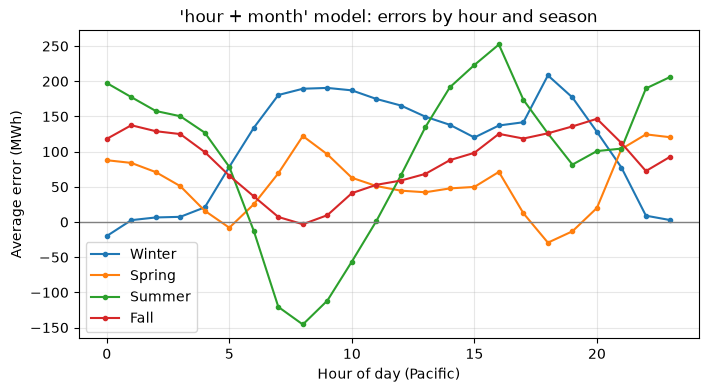

In [15]:
#
simple = LinearRegression(fit_intercept=False).fit(X_tr, train["demand_mwh"])
resid = valid["demand_mwh"] - simple.predict(X_va) #difference between actual demand and predicted
pred_hm = simple.predict(X_va)

season_names = {0: "Winter", 1: "Spring", 2: "Summer", 3: "Fall"}

fig, ax = plt.subplots(figsize=(8, 4))
for s, name in season_names.items():
    mask = valid["season"] == s
    by_hour = resid[mask].groupby(valid.loc[mask, "hour_pacific"]).mean()
    ax.plot(by_hour, marker="o", markersize=3, label=name)

ax.axhline(0, color="gray", linewidth=1)
ax.set_xlabel("Hour of day (Pacific)")
ax.set_ylabel("Average error (MWh)")
ax.set_title("'hour + month' model: errors by hour and season")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


We get a large variation for the summer swinging negative and positive. It is underpredicting the morning and over predicting the evenings/afternoons. What could be causing this? -To coarse of a comparison so we fit same shape onto every season so summer doesn't get its appropriate modeling to handle the correct demand changes. 
The winter become high ~hour 5 and then hold until the end of the day. 

In [16]:
results = [comparison(valid['demand_mwh'], simple.predict(X_va), "LR HM")]
results[0]

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,LR HM,194.27,2.9,245.64,-86.25


This is roughly the same MAPE seen before which is good confirmation as well for the matrix

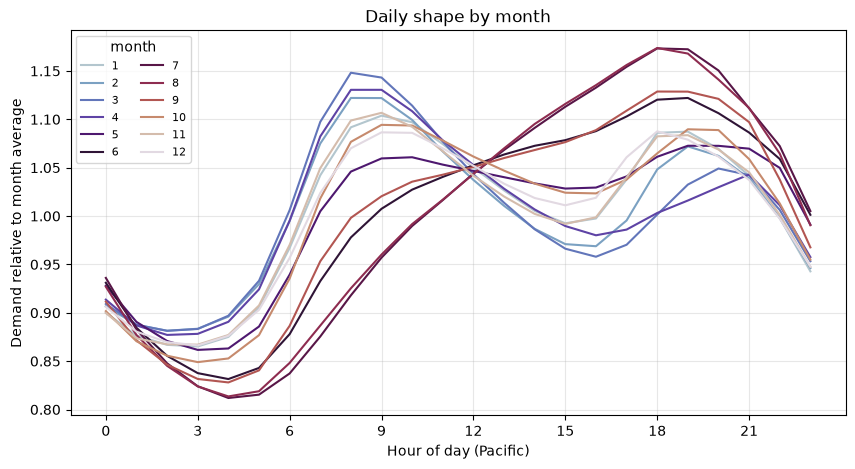

In [17]:
#avg daile shape for each month
#divide by month average to compare shapes
shape = train.groupby(["month","hour_pacific"])["demand_mwh"].mean().unstack("month")
shape = shape/shape.mean()

fig, ax = plt.subplots(figsize = (10,5))
for m in shape.columns:
    ax.plot(shape.index, shape[m], color=plt.cm.twilight(m/12), label=str(m))
ax.set_xticks(range(0,24,3))
ax.set_xlabel("Hour of day (Pacific)")
ax.set_ylabel("Demand relative to month average")
ax.set_title("Daily shape by month")
ax.legend(title='month',ncol=2,fontsize=8)
ax.grid(alpha=0.3)
plt.show()

March and april have largest morning(7-9) demand and July and August are lowest. 
July/August have largest evening(5-7) demand and february and march have lowest. 
Overall months in the same seasons have the same general shape, which is good for grouping but it isn't a perfect split seen with spring months looking like winter in mornings

In [18]:
#updated desgin function, test again
#season x hour
X_tr = design(train, "SH", WEATHER)
X_va = design(valid, "SH", WEATHER)
slot_flags = X_tr.filter(regex=r"^slot_")

print("columns:", X_tr.shape[1])  #expect 1 + 95 + 3 + 16 = 115
print("same columns as valid:", list(X_tr.columns) == list(X_va.columns)) #expect True
print("NaN count:", X_tr.isna().sum().sum())#expect 0
print("max slot flags per row:", slot_flags.sum(axis=1).max())#expect 1
print("no-slot-flag rows are winter midnight:",
      (slot_flags.sum(axis=1) == 0).sum() == ((train["season"] == 0) & (train["hour_pacific"] == 0)).sum())  #expect True

columns: 115
same columns as valid: True
NaN count: 0
max slot flags per row: 1
no-slot-flag rows are winter midnight: True


In [19]:
sh_simple = LinearRegression(fit_intercept=False).fit(X_tr, train['demand_mwh'])
pred_sh = sh_simple.predict(X_va)

results.append(comparison(valid["demand_mwh"],pred_sh, "Season x Hour LR"))
score = pd.concat(results)
score

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,LR HM,194.27,2.90,245.64,-86.25
0,Season x Hour LR,183.27,2.73,233.91,-66.29


An overall improvement to include the seasons

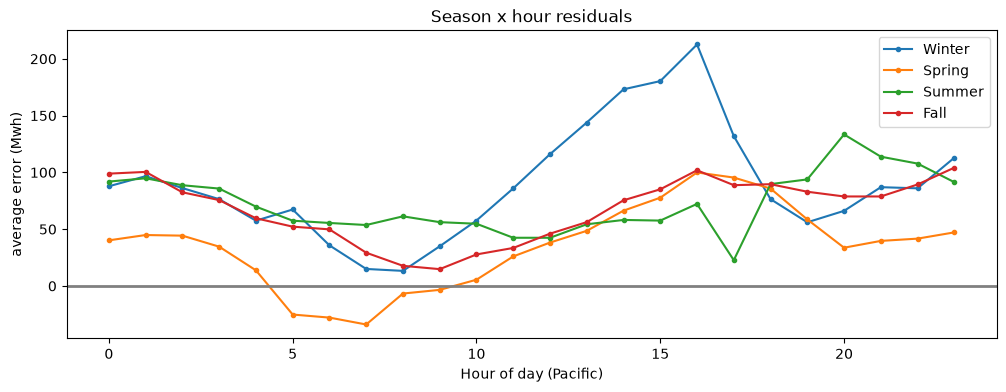

In [20]:
#plots of residuals by season
fig, ax = plt.subplots(figsize=(12,4))

resid = valid['demand_mwh'] - pred_sh
for s, name in season_names.items(): 
    mask = valid["season"] == s
    by_hour = resid[mask].groupby(valid.loc[mask,'hour_pacific']).mean()
    ax.plot(by_hour.index, by_hour.values, marker = 'o', markersize=3,label=name)

ax.axhline(0, color = 'gray',linewidth=2)
ax.set_xlabel('Hour of day (Pacific)')
ax.set_ylabel("average error (Mwh)")
ax.set_title('Season x hour residuals')
ax.legend()
plt.show()

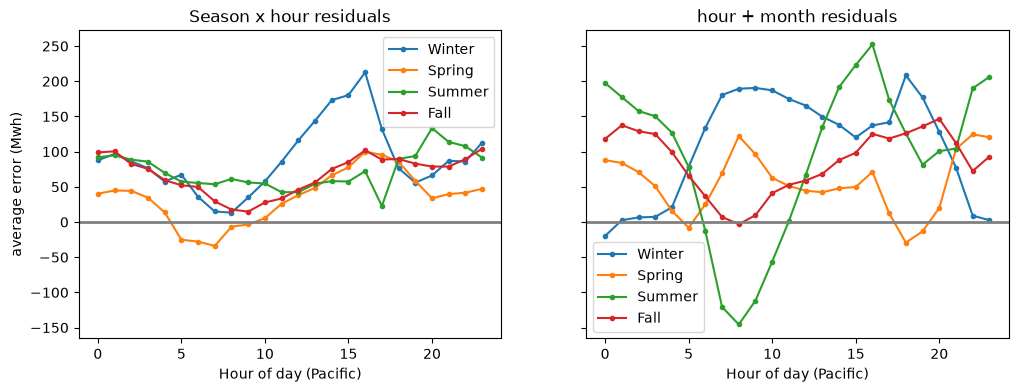

In [21]:
#plot side by side
#plots of residuals by season

fig, ax = plt.subplots(1,2,figsize=(12,4), sharey=True)

resid_sh = valid['demand_mwh'] - pred_sh
for s, name in season_names.items(): 
    mask = valid["season"] == s
    by_hour = resid_sh[mask].groupby(valid.loc[mask,'hour_pacific']).mean()
    ax[0].plot(by_hour.index, by_hour.values, marker = 'o', markersize=3,label=name)

ax[0].axhline(0, color = 'gray',linewidth=2)
ax[0].set_xlabel('Hour of day (Pacific)')
ax[0].set_title("Season x hour residuals")
ax[0].legend()


resid_mh = valid['demand_mwh'] - pred_hm
for s, name in season_names.items(): 
    mask = valid["season"] == s
    by_hour = resid_mh[mask].groupby(valid.loc[mask,'hour_pacific']).mean()
    ax[1].plot(by_hour.index, by_hour.values, marker = 'o', markersize=3,label=name)

ax[1].axhline(0, color = 'gray',linewidth=2)
ax[1].set_xlabel('Hour of day (Pacific)')
ax[1].set_title('hour + month residuals')
ax[1].legend()

ax[0].set_ylabel("average error (Mwh)")
plt.show()

The summer swing is gone with the season adjustment which is good! Still see the growth from before. 
Winter still has a later afternoon/evening bump so still missing something for winter but everything else is looking okay


In [22]:
#updated design again so quick check of update
#month x hour
X_tr = design(train, "MH", WEATHER)
X_va = design(valid, "MH", WEATHER)
mh_flags = X_tr.filter(regex=r"^mh_")

print("columns:", X_tr.shape[1]) #expect 1 + 287 + 3 + 16 = 307
print("same columns as valid:", list(X_tr.columns) == list(X_va.columns)) #expect True
print("NaN count:", X_tr.isna().sum().sum())#expect 0
print("max mh flags per row:", mh_flags.sum(axis=1).max())#expect 1
print("no-mh-flag rows are January midnight:",
      (mh_flags.sum(axis=1) == 0).sum() == ((train["month"] == 1) & (train["hour_pacific"] == 0)).sum())  #expect True

columns: 307
same columns as valid: True
NaN count: 0
max mh flags per row: 1
no-mh-flag rows are January midnight: True


In [23]:
MH_simple = LinearRegression(fit_intercept=False).fit(X_tr, train['demand_mwh'])
pred_mh = MH_simple.predict(X_va)

results.append(comparison(valid["demand_mwh"],pred_mh, "Month x Hour LR"))
score = pd.concat(results)
score

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,LR HM,194.27,2.90,245.64,-86.25
0,Season x Hour LR,183.27,2.73,233.91,-66.29
0,Month x Hour LR,183.37,2.73,232.71,-77.72


There is no improvement using the month x hour model and it includes more parameters to consider. 

These versions for how to treat the seasons show that the season x hour model is the best to use. 

## now look at weather more closely

Saw some correlation between hdh and hdh12 (also cooling) so will see if we need all of them or a subset. 
We will test each and take the one with lowest MAPE


In [24]:
WEATHER_SETS = {
    "current": col_names("hdh") + col_names("cdh"),
    "rolling12": col_names("hdh12") + col_names("cdh12"),
    "both": WEATHER,
}

rows = []
fits = {}   #keep each model and its columns for the coefficient check
for name, cols in WEATHER_SETS.items():
    X_tr = design(train, "HM", cols)
    X_va = design(valid, "HM", cols)
    ols = LinearRegression(fit_intercept=False).fit(X_tr, train["demand_mwh"])

    rows.append(comparison(valid["demand_mwh"], ols.predict(X_va), name))
    fits[name] = pd.Series(ols.coef_, index=X_tr.columns)

pd.concat(rows, ignore_index=True)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,current,257.44,3.85,323.54,-52.40
1,rolling12,243.50,3.61,317.34,-79.06
2,both,194.27,2.90,245.64,-86.25


having both does the best overall! We do see that just using current has the lowest bias though. 

In [25]:
#weather weights from each model, 
# one column per model (NaN where a model didn't have that feature)
coefs = pd.DataFrame({name: fits[name][WEATHER_SETS[name]] for name in WEATHER_SETS}).round(1)
coefs.sort_values(by='both')

,current,rolling12,both
vancouver_wash_cdh12,NaN,-2.8,-7.7
eugene_hdh12,NaN,4.9,-2.5
everett_cdh,-20.6,NaN,-0.2
kennewick_cdh,30.2,NaN,4.7
kennewick_hdh,22.2,NaN,5.2
eugene_cdh12,NaN,-5.7,7.2
eugene_cdh,-23.2,NaN,9.6
eugene_hdh,2.3,NaN,9.8
vancouver_wash_cdh,45.7,NaN,11.1
everett_hdh12,NaN,40.4,11.4


In [26]:
coefs #to see by region 

,current,rolling12,both
eugene_cdh,-23.2,NaN,9.6
eugene_cdh12,NaN,-5.7,7.2
eugene_hdh,2.3,NaN,9.8
eugene_hdh12,NaN,4.9,-2.5
everett_cdh,-20.6,NaN,-0.2
everett_cdh12,NaN,53.4,36.9
everett_hdh,35.3,NaN,26.8
everett_hdh12,NaN,40.4,11.4
kennewick_cdh,30.2,NaN,4.7
kennewick_cdh12,NaN,29.1,25.2


The negative values are something to watch out for, expected positive since neither should lower demand. 
Comparing regions we see:
- Negatives show up in every version, not just `both`: `current` has Eugene and Everett cooling at about −20, `rolling12` has Eugene and Vancouver cooling slightly negative, and `both` has Vancouver cdh12 (−7.7) and Eugene hdh12 (−2.5). So it isn't only the twins causing trouble.
- eating is stable once the twins are added together Summing each location's pair in `both` and comparing to the single-set weights (MWh per degree-hour):
- adding locations both and comparing current/rolling for hdh:

| location | current | rolling12 | both (hdh + hdh12) |
|---|---|---|---|
| eugene | 2.3 | 4.9 | 9.8 − 2.5 = 7.3 |
| everett | 35.3 | 40.4 | 26.8 + 11.4 = 38.2 |
| kennewick | 22.2 | 22.9 | 5.2 + 18.3 = 23.5 |
| vancouver_wash | 30.8 | 27.0 | 16.5 + 17.5 = 34.0 |

The total heating effect per location barely moves just how it's split between current and 12h changes which is what is expected from the high correlation

- Cooling is not stable-> Kennewick is the only one consistent (about 30 in every version: 30.2, 29.1, 4.7 + 25.2 = 29.9). But Eugene, Everett and Vancouver swing sign between versions (e.g. Vancouver cdh +45.7 in `current`, cdh12 −2.8 in `rolling12`; Everett cdh −20.6 in `current` but cdh12 +53.4 in `rolling12`).

- The cooling could be due similar locations or less data for cooling on hot days 
- locations also seem tied to heating as Eugene gets almost nothing while Everett and Vancouver get the most. This would me Eugene cold doesn't matter at all but that is suspicious and could see that it is tieing locations together such as Eugene and Vancouver (West) and so Vancouver takes the credit. 
- also note here Everett and Vancouver take more of the weight but earlier we said kennewich was the strongest

So:
- `both` wins clearly on MAPE 

In [27]:
#now use the SH model which was the best from before
WEATHER_SETS = {
    "current": col_names("hdh") + col_names("cdh"),
    "rolling12": col_names("hdh12") + col_names("cdh12"),
    "both": WEATHER,
}

rows = []
fits = {}   #keep each model and its columns for the coefficient check
for name, cols in WEATHER_SETS.items():
    X_tr = design(train, "SH", cols)
    X_va = design(valid, "SH", cols)
    ols = LinearRegression(fit_intercept=False).fit(X_tr, train["demand_mwh"])

    rows.append(comparison(valid["demand_mwh"], ols.predict(X_va), name))
    fits[name] = pd.Series(ols.coef_, index=X_tr.columns)

pd.concat(rows, ignore_index=True)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,current,224.75,3.37,284.05,-50.43
1,rolling12,214.36,3.19,275.96,-59.80
2,both,183.27,2.73,233.91,-66.29


Both is still better for MAPE and SH brings bias lower

In [28]:
coefs = pd.DataFrame({name: fits[name][WEATHER_SETS[name]] for name in WEATHER_SETS}).round(1)
coefs.sort_values(by='both')

,current,rolling12,both
vancouver_wash_cdh12,NaN,5.2,-4.9
eugene_hdh12,NaN,3.3,-3.2
eugene_cdh12,NaN,-5.4,-0.3
everett_cdh,2.8,NaN,1.7
kennewick_hdh,27.5,NaN,4.1
eugene_cdh,-14.0,NaN,5.9
eugene_hdh,3.5,NaN,8.4
kennewick_cdh,31.4,NaN,9.5
vancouver_wash_cdh,25.1,NaN,10.2
vancouver_wash_hdh,28.4,NaN,14.2


In [29]:
coefs

,current,rolling12,both
eugene_cdh,-14.0,NaN,5.9
eugene_cdh12,NaN,-5.4,-0.3
eugene_hdh,3.5,NaN,8.4
eugene_hdh12,NaN,3.3,-3.2
everett_cdh,2.8,NaN,1.7
everett_cdh12,NaN,33.9,29.5
everett_hdh,35.8,NaN,22.0
everett_hdh12,NaN,42.2,18.2
kennewick_cdh,31.4,NaN,9.5
kennewick_cdh12,NaN,33.3,24.2


With the better model:
- MAPE improves and bias shrinks and `both` still wins
- Does nothing for Heating
- Mostly fixes cooling as all totals in both are positive so part of weird cooling was due to HM missing summer
- the remaining negatives are mostly Eugene (hdh12 −3.2, cdh12 −0.3, and −14.0 for current cooling) plus Vancouver cdh12 (−4.9) inside a pair whose total is still positive. That points to Eugene being redundant with Vancouver (both Willamette Valley)

### Mixed sets: where does the gain from `both` come from?
`both` beats the single sets by about 0.5 points of MAPE. Two questions:
1. Is the gain from the **heating** twins, the **cooling** twins, or both? Mix and match: one side gets both versions, the other gets only one.
2. Is **Eugene** needed? If its information is already carried by Vancouver, dropping it should cost nothing and remove most of the negative weights.

**Rule:** lowest MAPE wins, but if another set is within about 0.05 points, prefer the one with fewer columns and fewer negative weights. Fewer correlated columns will matter more in the Bayesian model, where they slow down sampling.

In [30]:
#mixed sets, all with the SH shape
MIXED_SETS = {
    "both": WEATHER,
    "heat 12h + cool both": col_names("hdh12") + col_names("cdh") + col_names("cdh12"),
    "heat both + cool 12h": col_names("hdh") + col_names("hdh12") + col_names("cdh12"),
    "heat current + cool 12h": col_names("hdh") + col_names("cdh12"),
    "both, no eugene": [c for c in WEATHER if not c.startswith("eugene")],
}

rows = []
for name, cols in MIXED_SETS.items():
    X_tr = design(train, "SH", cols)
    X_va = design(valid, "SH", cols)
    ols = LinearRegression(fit_intercept=False).fit(X_tr, train["demand_mwh"])
    fits[name] = pd.Series(ols.coef_, index=X_tr.columns)   #keep weights for the check below

    score = comparison(valid["demand_mwh"], ols.predict(X_va), name)
    score["n_weather"] = len(cols)
    score["n_negative"] = (fits[name][cols] < 0).sum()   #weather weights below zero
    rows.append(score)

mixed = pd.concat(rows, ignore_index=True)
mixed

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,n_weather,n_negative
0,both,183.27,2.73,233.91,-66.29,16,3
1,heat 12h + cool both,197.02,2.93,252.74,-60.29,12,2
2,heat both + cool 12h,190.97,2.84,245.86,-69.32,12,1
3,heat current + cool 12h,195.97,2.91,254.91,-70.14,8,0
4,"both, no eugene",182.80,2.72,233.12,-63.31,12,1


**What the mixed sets show:**
- **The gain comes from both sides.** Twins on heating only (`heat both + cool 12h`, 2.84) or on cooling only (`heat 12h + cool both`, 2.93) each recover part of the gap; together (`both`, 2.73) is best. So current + 12h carry *different* timing information on both sides, even though the heating twins are 0.86–0.94 correlated.
- **`heat current + cool 12h` is the only set with no negative weights**, but costs about 0.2 points of MAPE (2.91).
- **Dropping Eugene costs nothing:** 2.72 vs 2.73, with 4 fewer columns and only 1 negative weight left. That confirms Eugene's information is already carried by the other locations (mostly Vancouver).

Check the one remaining negative: does each location's twin pair still add up to something sensible?

In [31]:
#twin-pair weights and totals per location for the no-eugene set
w = fits["both, no eugene"]
pairs = pd.DataFrame({
    loc: {
        "hdh": w[f"{loc}_hdh"], "hdh12": w[f"{loc}_hdh12"], "heat total": w[f"{loc}_hdh"] + w[f"{loc}_hdh12"],
        "cdh": w[f"{loc}_cdh"], "cdh12": w[f"{loc}_cdh12"], "cool total": w[f"{loc}_cdh"] + w[f"{loc}_cdh12"],
    }
    for loc in LOCATIONS if loc != "eugene"
}).T.round(1)
pairs

,hdh,hdh12,heat total,cdh,cdh12,cool total
everett,23.6,17.8,41.4,2.9,28.1,31.0
kennewick,5.2,20.0,25.1,9.6,24.5,34.1
vancouver_wash,19.8,15.6,35.4,15.0,-5.8,9.1


The only negative left is Vancouver cdh12 and its pair total is still positive (15.0 − 5.8 = 9.2), so that's credit-splitting inside a twin pair, not "heat lowers demand". Every heating and cooling total is positive and Vancouver's heating total went up by about Eugene's old share, which fits Vancouver picking up Eugene's information.

## Decision: weather set
**Use `both, no eugene`:** current and 12h heating and cooling degree-hours for Everett, Kennewick and Vancouver WA (12 columns), with the `SH` shape.
- Best validation MAPE (2.72%), tied with `both` but 4 fewer columns.
- Fewest negative weights of the high-scoring sets, and every location total makes physical sense.
- Fewer correlated columns means easier sampling in the Bayesian model.

**How to read it:** individual twin weights aren't meaningful on their own; the per-location totals are. The Bayesian model should report those totals with their uncertainty.

**Trade-off noted:** Eugene is out of the model. That's a coverage loss for the southern Willamette Valley, but in this data its weather moves with Vancouver's closely enough that the model can't use it separately.

In [32]:
#final weather set for everything after this
ALL_WEATHER = MIXED_SETS["both, no eugene"]
print(len(ALL_WEATHER), "weather columns:\n", ALL_WEATHER) 

12 weather columns:
 ['everett_hdh', 'kennewick_hdh', 'vancouver_wash_hdh', 'everett_cdh', 'kennewick_cdh', 'vancouver_wash_cdh', 'everett_hdh12', 'kennewick_hdh12', 'vancouver_wash_hdh12', 'everett_cdh12', 'kennewick_cdh12', 'vancouver_wash_cdh12']


## Bayesian 

In [33]:
X_tr = design(train,'SH', ALL_WEATHER)
X_va = design(valid, 'SH', ALL_WEATHER)

ols_final = LinearRegression(fit_intercept=False).fit(X_tr,train['demand_mwh'])
pred_ols = ols_final.predict(X_va)

ols_score = [comparison(valid['demand_mwh'],pred_ols, 'OLS_ref')]
print(ols_score[0])

ols_ref = pd.Series(ols_final.coef_, index = X_tr.columns)

     model  mae_mwh  mape_pct  rmse_mwh  bias_mwh
0  OLS_ref    182.8      2.72    233.12    -63.31


Ignored until now is different scaling of values for colummns: i.e weather ~30, intercept~1,000 so rescale everything so choosing priors is equivalent and sample can move through parameters better
Normalizing the parameters to 1

In [34]:
#scale demand by 1000 since usually value in thousands
DEMAND_SCALE = 1000
#scale weather by 10 since seeing things in the 10s
WEATHER_SCALE = 10 

def scale_X(X):
    """ Takes the data and scales it """
    X = X.astype(float).copy() #make consistent type 
    X[ALL_WEATHER] = X[ALL_WEATHER] / WEATHER_SCALE
    return X

#refit with scaled data - the results should stay the same
X_trs = scale_X(X_tr)
X_vas = scale_X(X_va)
y_trs = train["demand_mwh"] / DEMAND_SCALE

In [35]:
#check scaling by LR and making sure we can get back what we had before
ols_s = LinearRegression(fit_intercept=False).fit(X_trs, y_trs)
pred_s = ols_s.predict(X_vas) * DEMAND_SCALE  #back to MWh

#check same predictions
print("max prediction difference (MWh):", np.abs(pred_ols - pred_s).max()) 
display(comparison(valid["demand_mwh"], pred_s, "OLS scaled"))#expect same MAPE as above

#weights convert back
coef_s = pd.Series(ols_s.coef_, index=X_trs.columns)

back = coef_s * DEMAND_SCALE  #undo the demand scaling
back[ALL_WEATHER] = back[ALL_WEATHER] / WEATHER_SCALE  #undo the weather scaling
print("max weight difference:", np.abs(back - ols_ref).max())


max prediction difference (MWh): 6.530171958729625e-10


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,OLS scaled,182.8,2.72,233.12,-63.31


max weight difference: 6.605773705814499e-10


Awesome get the same results back

In [36]:
#how big are the scaled weights? sets the prior widths in the next step
display(coef_s.abs().describe().round(2))
coef_s[["intercept", "years_since_start", "is_weekend", "is_major_holiday"] + ALL_WEATHER].round(3)

count    111.00
mean       0.71
std        0.56
min        0.02
25%        0.26
50%        0.77
75%        1.04
max        4.51
dtype: float64

intercept               4.511
years_since_start       0.097
is_weekend             -0.324
is_major_holiday       -0.235
everett_hdh             0.236
kennewick_hdh           0.052
vancouver_wash_hdh      0.198
everett_cdh             0.029
kennewick_cdh           0.096
vancouver_wash_cdh      0.150
everett_hdh12           0.178
kennewick_hdh12         0.200
vancouver_wash_hdh12    0.156
everett_cdh12           0.281
kennewick_cdh12         0.245
vancouver_wash_cdh12   -0.058
dtype: float64

*Size of the scaled weights: 
the median is about 0.8 and almost everything is below 2. 
The one outlier is the intercept which is the demand level of the reference case (winter, midnight, weekday, zero degree-hours, year 0) in thousands of MWh, while every other weight is a difference from it. So one prior can't fit every weight and the intercept will need its own prior centered on a typical demand level.

## Step 3 -> Small random subset
The first PyMC runs will have mistakes (shapes, names, priors). On ~3,000 rows each try takes seconds instead of minutes. A *random* sample, not every Nth row: hourly data with every 10th row would only ever land on even hours (10 and 24 share a factor of 2).

In [37]:
sub = train.sample(3000, random_state=42) #small subset for testing

In [38]:
(sub["season"]*24 + sub["hour_pacific"]).value_counts()

67    44
53    43
49    42
70    42
45    42
      ..
1     22
73    22
84    21
29    20
7     20
Name: count, Length: 96, dtype: int64

All 96 season x hour slots show up, with 20–44 rows each, so every slot weight gets data (a slot with 0 rows would be set by its prior alone).

Now take the matching rows of the **scaled** design matrix. `train` was `reset_index`'d and `design()` keeps that index, so `sub.index` points at the same rows in `X_trs` and `y_trs`.

In [39]:
#subset rows of the scaled matrix and scaled demand
X_sub = X_trs.loc[sub.index]
y_sub = y_trs.loc[sub.index]

print(X_sub.shape, y_sub.shape)   #expect (3000, 111) (3000,)
print("same rows:", (X_sub.index == y_sub.index).all())   #expect True

(3000, 111) (3000,)
same rows: True


## Step 4 -> The first Bayesian model

Same model as OLS, written as a story of how the data is generated:

```
demand_scaled ~ Normal(mu, sigma)
mu = X @ beta <- the same weighted sum OLS uses
beta ~ Normal(0, prior_sd) <- what we believe about each weight before seeing data
sigma ~ HalfNormal(1) <- how far actual demand sits from the line (noise)
```

What's new compared to OLS:
- **`beta` is a distribution, not one number.** After sampling, each weight has a full range of plausible values, which is where "effects with uncertainty" comes from.
- **`sigma` is explicit.** OLS never reports it, but it sets the width of the prediction interval. It's `HalfNormal` because noise can't be negative.
- **Priors.** Every weight needs one we start simple, `Normal(0, 5)` for every weight, and let a prior check later say whether that's sensible, rather than guessing.

Code pieces:
- `coords` / `dims="feature"` attach the column names to `beta`, so results come back labeled (`beta["kennewick_hdh12"]`) instead of as position 107.
- `pm.Data` wraps the inputs so the 2024 data can be swapped in later for predictions without rebuilding the model.
- `shape=X_data.shape[0]` lets the number of predictions follow whatever data is plugged in. Without it, predicting on the 8,784 valid hours fails because the model expects 3,000.

In [40]:
coords = {'feature': X_sub.columns}

with pm.Model(coords=coords) as m0:
    X_data = pm.Data("X", X_sub.values) #inputs, swappable later
    y_data = pm.Data("y_obs", y_sub.values) #observed demand (thousands of MWh)

    beta = pm.Normal("beta", mu=0, sigma=5, dims="feature") #one weight per column, wide on purpose
    sigma = pm.HalfNormal("sigma", sigma=1) #noise, in thousands of MWh

    mu = X_data @ beta #the weighted sum
    pm.Normal("y", mu=mu, sigma=sigma, observed=y_data, shape=X_data.shape[0])

m0

 beta ~ Normal(0, 5)
sigma ~ HalfNormal(0, 1)
    y ~ Normal(f(beta), sigma)

## Step 5 -> Prior predictive check
Before the model sees any data: 
what demand does it think is possible? 
    Draw weights from the priors, push them through `X @ beta` plus noise, and compare the simulated demand with real demand.

Plausible = mostly within about 0–20,000 MWh and centered somewhere near real demand. 

In [41]:
def prior_check(model, title):
    """
    Draw demand from the priors only and compare to real demand (both in MWh)
    """
    with model:
        prior = pm.sample_prior_predictive(500, random_seed=42)

    sim = prior.prior_predictive["y"].values.ravel() * DEMAND_SCALE  #all simulated hours, back to MWh
    real = y_sub.values * DEMAND_SCALE

    print(f"simulated 5%-95%: {np.percentile(sim, 5):,.0f} to {np.percentile(sim, 95):,.0f} MWh")
    print(f"simulated median: {np.median(sim):,.0f} MWh  (real median {np.median(real):,.0f})")
    print(f"share negative: {(sim < 0).mean():.1%}")

    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(sim, bins=100, density=True, alpha=0.6, label="prior predictive")
    ax.hist(real, bins=50, density=True, alpha=0.6, label="real demand")

    ax.axvline(0, color="gray", linewidth=1)

    ax.set_xlabel("Demand (MWh)")
    ax.set_title(title)
    ax.legend()
    plt.show()
    return prior



Sampling: [beta, sigma, y]


simulated 5%-95%: -38,611 to 36,967 MWh
simulated median: -1,016 MWh  (real median 6,438)
share negative: 52.0%


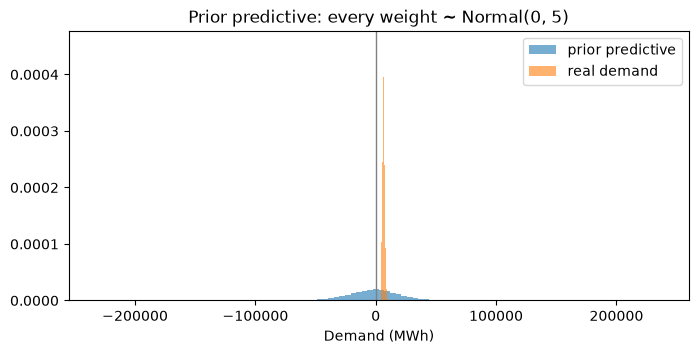

In [42]:
prior_m0 = prior_check(m0, "Prior predictive: every weight ~ Normal(0, 5)")

Way too wide!
The 5–95% range runs from about −39,000 to +37,000 MWh and about half the simulated hours are negative demand. 
Each hour adds up roughly 15+ weights (intercept, one slot, calendar, 12 weather columns with values up to ~6 after scaling), and each one swinging by plus/minus 5 thousand MWh adds up to something huge. So `Normal(0, 5)` isn't "neutral". It says the model believes −40,000 MWh is about as likely as 7,000.

### Adjusting the priors
Use what is already known about demand from EDA, not the OLS fit. 
Setting priors from the fit on the same data would count that data twice:

| weights | prior | why (in thousands of MWh) |
|---|---|---|
| intercept | Normal(7, 2) | BPA demand averages ~6,500–7,000 MWh; $\pm$2 covers ~3,000–11,000 |
| season x hour slots | Normal(0, 1.5) | daily/seasonal swings were up to ~1,500–2,000 MWh |
| weekend, holiday, trend | Normal(0, 0.5) | weekends ~−300, holidays up to ~−1,000, growth ~100–300 per year |
| weather (per 10 degree-hours) | Normal(0, 0.5) | allows up to ~$\pm$1,000 MWh per 10 degree-hours per location |

These are still weakly informative wide enough that 26k hours of data will easily overrule them, but they rule out absurd values. The weather priors are still centered on 0, not forced positive. 

Sampling: [beta, sigma, y]


columns without a prior: 0


simulated 5%-95%: 1,287 to 12,616 MWh
simulated median: 6,755 MWh  (real median 6,438)
share negative: 2.2%


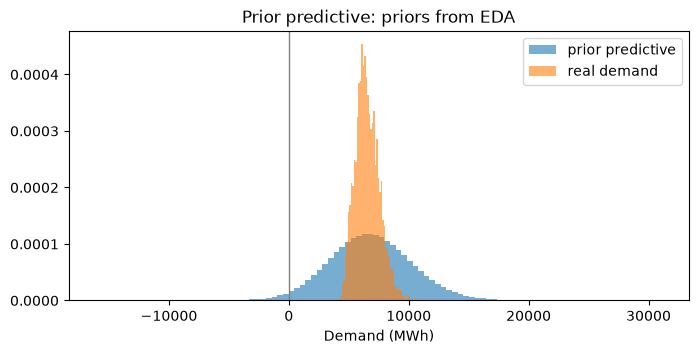

In [43]:
#one prior mean and width per column 
#built by column name so the order always matches X

cols = X_sub.columns
prior_mu = pd.Series(0.0, index=cols)
prior_sd = pd.Series(np.nan, index=cols)

#set up prior information
prior_mu["intercept"] = 7.0
prior_sd["intercept"] = 2.0
prior_sd[cols.str.startswith("slot_")] = 1.5
prior_sd[["is_weekend", "is_major_holiday", "years_since_start"]] = 0.5
prior_sd[ALL_WEATHER] = 0.5

print("columns without a prior:", prior_sd.isna().sum()) #expect 0, every weight needs one

with pm.Model(coords=coords) as m1:
    X_data = pm.Data("X", X_sub.values)
    y_data = pm.Data("y_obs", y_sub.values)

    beta = pm.Normal("beta", mu=prior_mu.values, sigma=prior_sd.values, dims="feature")
    sigma = pm.HalfNormal("sigma", sigma=1)

    mu = X_data @ beta
    pm.Normal("y", mu=mu, sigma=sigma, observed=y_data, shape=X_data.shape[0])

prior_m1 = prior_check(m1, "Prior predictive: priors from EDA")

Much better
The 5–95% range is now about 1,300 to 12,600 MWh, centered near real demand (median ~6,800 vs ~6,400 real), and only ~2% of simulated hours are negative. It's still clearly wider than real demand, which is what weakly informative priors should look like as the model is allowed to be surprised, but not absurd.

use `m1`'s priors

### sample subset of data with model
 sample `m1` on the subset

In [44]:
import time

In [45]:
with m1:
    start = time.time()
    idata = pm.sample(draws=1000, tune=1000, chains=4, nuts_sampler="nutpie", #no u-turn sampling
                            random_seed=SEED)
    print(f'sampling time: {time.time() - start:.0f} s')

Progress,Draws,Divergences,Step Size,Gradients/Draw
,2000,0,0.19,15
,2000,0,0.19,95
,2000,0,0.20,15
,2000,0,0.17,15


sampling time: 113 s


In [46]:
#now check output
summary = az.summary(idata, var_names=["beta", "sigma"])

print("max r_hat:", summary["r_hat"].max()) #want < 1.01
print("weights with r_hat > 1.01:", (summary["r_hat"] > 1.01).sum())
print("min ESS (bulk):", summary["ess_bulk"].min()) #want > 400
print("weights with ESS < 400:", (summary["ess_bulk"] < 400).sum())
print("divergences:", int(idata.sample_stats["diverging"].sum())) #want 0

#the worst-sampled weights
summary.sort_values("ess_bulk")[["mean", "sd", "ess_bulk", "r_hat"]].head(10)

max r_hat: 1.04
weights with r_hat > 1.01: 100
min ESS (bulk): 97.0
weights with ESS < 400: 101
divergences: 0


,mean,sd,ess_bulk,r_hat
beta[intercept],4.656,0.059,97.0,1.04
beta[slot_34],0.940,0.071,130.0,1.03
beta[slot_58],0.931,0.073,130.0,1.04
beta[slot_86],0.678,0.071,130.0,1.03
beta[slot_93],0.769,0.067,131.0,1.03
beta[slot_35],0.831,0.074,131.0,1.03
beta[slot_41],0.593,0.072,132.0,1.03
beta[slot_59],0.989,0.075,133.0,1.04
beta[slot_61],1.039,0.074,134.0,1.03
beta[slot_37],0.700,0.075,135.0,1.03


The r-hat isn't showing convergence for all with 100 greater than the threshold

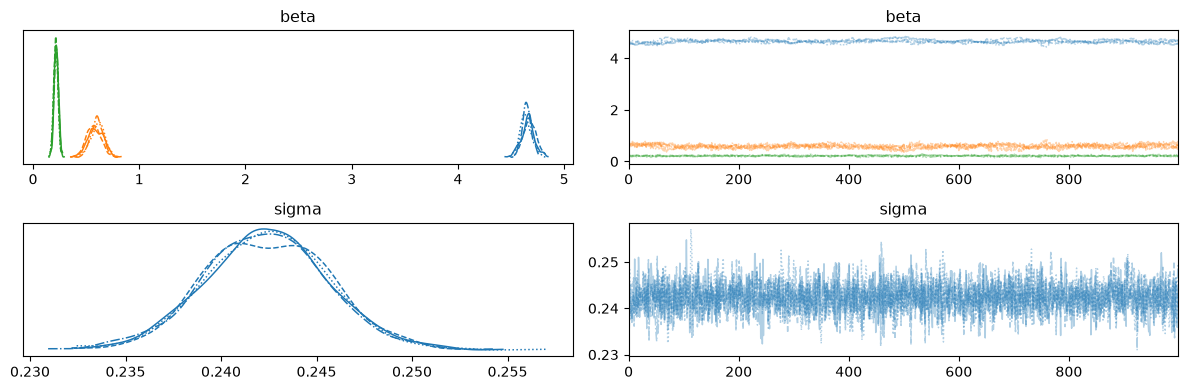

In [47]:
#plot traces
az.plot_trace(idata, var_names=["beta", "sigma"],
              coords={"feature": ["intercept", "slot_41", "kennewick_hdh12"]}) 
plt.tight_layout()
plt.show()

correlation: 0.9994
largest difference: 0.072 on slot_62


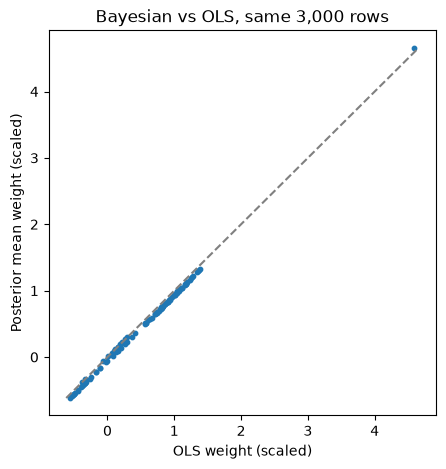

noise sigma: 242 MWh


In [48]:
#compare with OLS
ols_sub = LinearRegression(fit_intercept=False).fit(X_sub, y_sub)
ols_sub_w = pd.Series(ols_sub.coef_, index=X_sub.columns)

post_mean = idata.posterior["beta"].mean(dim=("chain", "draw")).to_series() #one number per weight

print("correlation:", np.corrcoef(post_mean, ols_sub_w)[0, 1].round(4))  #expect ~1
print("largest difference:", (post_mean - ols_sub_w).abs().max().round(3),
      "on", (post_mean - ols_sub_w).abs().idxmax())

fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(ols_sub_w, post_mean, s=10)

lims = [min(ols_sub_w.min(), post_mean.min()), max(ols_sub_w.max(), post_mean.max())]
ax.plot(lims, lims, color="gray", linestyle="--")   #points on this line = same answer

ax.set_xlabel("OLS weight (scaled)")
ax.set_ylabel("Posterior mean weight (scaled)")
ax.set_title("Bayesian vs OLS, same 3,000 rows")
plt.show()

print("noise sigma:", round(float(idata.posterior["sigma"].mean()) * DEMAND_SCALE), "MWh")


So we are getting the same answers which is good for model check but based on convergence the sampler is ineffecient/struggling

## Step 7 -> Fixing the sampler
The weights come out right but the sampler is inefficient with about 100 weights above r_hat 1.01 and ESS as low as 100.
A common cause is weights that move together in the posterior such that raising one forces others down, the sampler has to move many weights at once in a narrow direction leading to ineffeciency. 

Check which weights the intercept is correlated with to see if we can remedy this

In [49]:
#check which weights move together in the posterior
draws = idata.posterior["beta"].stack(sample=("chain", "draw")).to_pandas().T  #rows = draws, columns = weights
corr_int = draws.corr()["intercept"].drop("intercept")

print("average correlation, intercept vs slots:",
      corr_int[corr_int.index.str.startswith("slot_")].mean().round(2))
corr_int.abs().sort_values(ascending=False).head(5).round(2)

average correlation, intercept vs slots: -0.73


feature
slot_93    0.80
slot_86    0.79
slot_41    0.79
slot_91    0.79
slot_77    0.78
Name: intercept, dtype: float64

The intercept is strongly **negatively** correlated with the slot weights. 
- the intercept is the demand level of the reference slot (winter midnight), pinned down by only a few rows in this subset
- every other slot weight is a difference from that level
- if the intercept moves up a little, all 95 slot weights must move down by the same amount to keep the same predictions

So the sampler is forced to move the weights together. OLS doesn't care (it solves for everything at once), but a sampler that explores one region at a time does.

### Fix: give every slot its own level, no intercept
Replace `intercept + 95 slot differences` with **96 slot levels**: add `slot_0` back (1 for winter midnight rows, the old reference) and drop the intercept. Every hour is in exactly one slot, so each row still gets exactly one "base level".

This is the same model with different bookkeeping:
 the set of possible fits is identical, so predictions can't change. Only the meaning of the weights changes. Before, `slot_41` = "difference from winter midnight"; now `slot_41` = "demand level in that slot" (at zero degree-hours, weekday, year 0). Nothing depends on a shared reference anymore.

In [50]:
def full_slots(X):
    '''
    Replace intercept + 95 slot differences with 96 slot levels
    '''
    X = X.drop(columns="intercept").copy()
    slot_0 = 1 - X.filter(regex=r"^slot_").sum(axis=1) #1 only for winter midnight rows 
    X.insert(0, "slot_0", slot_0)
    return X

X_sub_f = full_slots(X_sub)
slot_cols = X_sub_f.filter(regex=r"^slot_")

print("shape:", X_sub_f.shape)   #expect (3000, 111) as we lost intercept, gained slot_0
print("slot flags per row:", slot_cols.sum(axis=1).unique()) #expect [1.] since every hour in exactly one slot

#predictions must not change
p_old = LinearRegression(fit_intercept=False).fit(X_sub, y_sub).predict(X_sub)
p_new = LinearRegression(fit_intercept=False).fit(X_sub_f, y_sub).predict(X_sub_f)
print("max prediction difference (MWh):", np.abs(p_old - p_new).max() * DEMAND_SCALE)   #expect ~0

shape: (3000, 111)
slot flags per row: [1.]
max prediction difference (MWh): 1.0835776720341528e-10


**Priors for the new version:** each slot weight is now a demand level, so slots get what the intercept had, `Normal(7, 2)` (thousands of MWh). Everything else is unchanged.

The model is the same as `m1`, so it goes into two small helpers, `make_priors` and `build_model`.
One model definition used everywhere means no copy-paste differences between versions. 
`sample` and `diagnostics` do the same for the sampling and the checks.

Sampling: [beta, sigma, y]


simulated 5%-95%: 1,845 to 12,071 MWh
simulated median: 6,924 MWh  (real median 6,438)
share negative: 1.6%


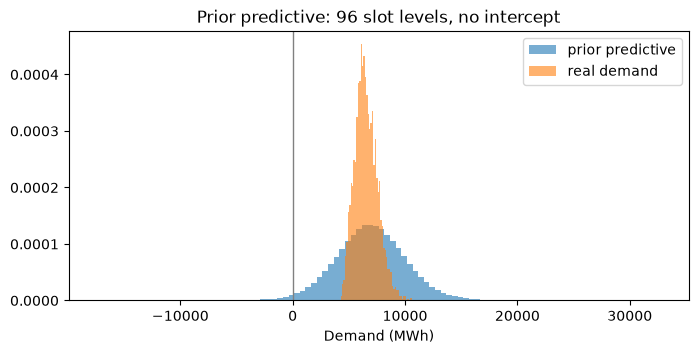

In [51]:
#turning steps above into functions for quick reproducibility between versions
#added fix for removing intercept
def make_priors(cols, weather_cols):
    '''
    Prior mean and width per column (thousands of MWh), set by column name
    '''
    mu = pd.Series(0.0, index=cols)
    sd = pd.Series(np.nan, index=cols)

    slots = cols.str.startswith("slot_")
    mu[slots] = 7.0 #each slot is now a demand level
    sd[slots] = 2.0
    sd[["is_weekend", "is_major_holiday", "years_since_start"]] = 0.5
    sd[weather_cols] = 0.5

    assert sd.notna().all(), "every column needs a prior"
    return mu, sd


def build_model(X, y, weather_cols):
    '''
    Bayesian linear model: demand ~ Normal(X @ beta, sigma), priors from EDA
    '''
    mu_p, sd_p = make_priors(X.columns, weather_cols)

    with pm.Model(coords={"feature": X.columns}) as model:
        X_data = pm.Data("X", X.values)
        y_data = pm.Data("y_obs", y.values)

        beta = pm.Normal("beta", mu=mu_p.values, sigma=sd_p.values, dims="feature")
        sigma = pm.HalfNormal("sigma", sigma=1)

        pm.Normal("y", mu=X_data @ beta, sigma=sigma, observed=y_data, shape=X_data.shape[0])
    return model


def sample(model):
    '''
    Same sampler settings as m1
    '''
    with model:
        start = time.time()
        idata = pm.sample(draws=1000, tune=1000, chains=4, nuts_sampler="nutpie",
                          random_seed=SEED, progressbar=False)
    print(f"sampling time: {time.time() - start:.0f} s")
    return idata


def diagnostics(idata, name):
    '''
    The three convergence checks in one row
    '''
    s = az.summary(idata, var_names=["beta", "sigma"])
    return pd.DataFrame({
        "model": [name],
        "max_r_hat": [s["r_hat"].max()],
        "n_r_hat_over_1.01": [(s["r_hat"] > 1.01).sum()],
        "min_ess_bulk": [s["ess_bulk"].min()],
        "n_ess_under_400": [(s["ess_bulk"] < 400).sum()],
        "divergences": [int(idata.sample_stats["diverging"].sum())],
    })


m2 = build_model(X_sub_f, y_sub, ALL_WEATHER)
prior_m2 = prior_check(m2, "Prior predictive: 96 slot levels, no intercept")

Still plausible: 5–95% of about 1,800 to 12,100 MWh, median ~6,900 (real ~6,400), ~1.6% negative. A little narrower than `m1` because each hour now gets one level prior instead of intercept + slot difference added together. 
weakly informative.

In [52]:
idata_m2 = sample(m2)

pd.concat([diagnostics(idata, "m1: intercept + 95 slot differences"),
           diagnostics(idata_m2, "m2: 96 slot levels")], ignore_index=True)

sampling time: 126 s


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m1: intercept + 95 slot differences,1.04,100,97.0,101,0
1,m2: 96 slot levels,1.01,0,624.0,0,0


In [53]:
#compare predictions on the subset 
pred_m1 = X_sub.values @ idata.posterior["beta"].mean(dim=("chain", "draw")).values
pred_m2 = X_sub_f.values @ idata_m2.posterior["beta"].mean(dim=("chain", "draw")).values
print("max prediction difference m1 vs m2 (MWh):", round(np.abs(pred_m1 - pred_m2).max() * DEMAND_SCALE, 1))

#check converengence
az.summary(idata_m2, var_names=["beta"]).sort_values("ess_bulk")[["mean", "sd", "ess_bulk", "r_hat"]].head(6)

max prediction difference m1 vs m2 (MWh): 63.6


,mean,sd,ess_bulk,r_hat
beta[kennewick_cdh],0.108,0.021,624.0,1.01
beta[kennewick_hdh12],0.218,0.022,639.0,1.01
beta[kennewick_hdh],0.065,0.021,648.0,1.01
beta[kennewick_cdh12],0.219,0.022,655.0,1.01
beta[vancouver_wash_cdh],0.150,0.027,696.0,1.00
beta[vancouver_wash_hdh12],0.193,0.030,724.0,1.00


So it works for efficiency as r_hat and ESS are all now within their values. 

We also see in comparison bewteen models that:
- The prediction barely moves. There is a 64 Mwh difference but that is less than the noise. 
- Sampling time is still about the same so we didn't lose time adding another slot
- Based on convergence the cooling and heating weights are hardest to sample which matches with them having correlations and moving together

We will use this version

## Step 8 -> Adding Eugene back
Eugene was dropped earlier because, in OLS, its weights split credit with Vancouver's  
    - some went negative and they swung between versions. OLS gives one number per weight, so it can only show that splitting as unstable or odd-looking weights.

The Bayesian model can show it directly:
- if Eugene and Vancouver carry the same information, their weights should be negatively correlated in the posterior (more credit to one = less to the other), with wide intervals
- their combined effect should still be tight, and close to Vancouver's alone in `m2`


We are going to run this with Eugene back in and we will keep Eugene only if it improves validation accuracy (by more than ~0.05 points of MAPE). 
Otherwise the simpler `m2` stays, since extra columns that only split credit add uncertainty without adding information.

`build_X` puts the steps from above (design -> scale weather -> 96 slot levels) in one helper, so any weather set goes through exactly the same steps. The first check confirms it reproduces the `m2` matrix.

In [54]:
def build_X(data, weather_cols):
    '''
    Design matrix -> scaled weather -> 96 slot levels, for any weather set
    '''
    X = design(data, "SH", weather_cols).astype(float)
    X[weather_cols] = X[weather_cols] / WEATHER_SCALE
    return full_slots(X)

#helper gives the same matrix m2 used
check = build_X(train, ALL_WEATHER).loc[sub.index]
print("matches m2 matrix:", list(check.columns) == list(X_sub_f.columns) and np.allclose(check, X_sub_f)) #expect True


matches m2 matrix: True


In [55]:
X_sub_e = build_X(train, WEATHER).loc[sub.index] #all 16 weather columns, Eugene included
print("shape:", X_sub_e.shape) #expect (3000, 115)

m3 = build_model(X_sub_e, y_sub, WEATHER)
idata_m3 = sample(m3)

pd.concat([diagnostics(idata_m2, "m2: no Eugene"),
           diagnostics(idata_m3, "m3: with Eugene")], ignore_index=True)

shape: (3000, 115)


sampling time: 179 s


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m2: no Eugene,1.01,0,624.0,0,0
1,m3: with Eugene,1.01,0,1009.0,0,0


### Check if Eugene helps

Score both on the 2024 validation year using the posterior mean weights as a point forecast. 
Both were fit on the same 3,000-hour subset

In [56]:
def predict_mean(idata, X):
    '''
    Point forecast in MWh from the posterior mean weights
    '''
    w = idata.posterior["beta"].mean(dim=("chain", "draw")).to_series()
    return X.values @ w[X.columns].values * DEMAND_SCALE

pd.concat([
    comparison(valid["demand_mwh"], predict_mean(idata_m2, build_X(valid, ALL_WEATHER)), "m2: no Eugene"),
    comparison(valid["demand_mwh"], predict_mean(idata_m3, build_X(valid, WEATHER)), "m3: with Eugene"),
], ignore_index=True)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,m2: no Eugene,188.53,2.80,241.84,-70.56
1,m3: with Eugene,188.74,2.81,242.39,-73.66


So including Eugene doesn't help any of the test

### Where is the information from Eugene being seenz

Lets look at location totals instead of the split meaning check Vancouver + Eugene which we saw tied together earlier and see if this is where the information is likely staying

In [57]:
#helper to get the totals 
def location_totals(idata, weather_cols):
    '''
    Heating and cooling total per location (current + 12h weight) in MWh per degree-hour, with 94% interval
    '''
    post = idata.posterior["beta"]
    to_mwh = DEMAND_SCALE / WEATHER_SCALE  #scaled weight -> MWh per degree-hour

    rows = []
    for loc in LOCATIONS:
        for kind, (a, b) in {"heat": ("hdh", "hdh12"), "cool": ("cdh", "cdh12")}.items():
            if f"{loc}_{a}" not in weather_cols: #check if we have the column
                continue

            total = ((post.sel(feature=f"{loc}_{a}") + post.sel(feature=f"{loc}_{b}")) * to_mwh).values.ravel() #choose correct params from posterior and flatten
            lo, mid, hi = np.percentile(total, [3, 50, 97]) #calculate intervals
            rows.append({"location": loc, "kind": kind, "median": mid, "low": lo, "high": hi}) #add to data

    return pd.DataFrame(rows).round(1)

In [58]:
totals = location_totals(idata_m2, ALL_WEATHER).merge(
    location_totals(idata_m3, WEATHER), on=["location", "kind"], how="outer", suffixes=(" m2", " m3")) #combine model datas on the same location and type

totals.sort_values(["kind", "location"])

,location,kind,median m2,low m2,high m2,median m3,low m3,high m3
0,eugene,cool,NaN,NaN,NaN,6.3,-0.2,13.0
2,everett,cool,31.2,23.8,38.2,31.2,23.3,38.7
4,kennewick,cool,32.7,30.2,35.3,32.3,29.7,34.7
6,vancouver_wash,cool,8.5,3.4,14.0,4.3,-3.3,12.1
1,eugene,heat,NaN,NaN,NaN,4.9,1.6,8.3
3,everett,heat,37.1,33.1,40.7,35.8,32.0,39.7
5,kennewick,heat,28.3,25.8,30.6,28.3,25.9,30.7
7,vancouver_wash,heat,34.8,31.0,38.7,31.5,26.7,36.1


In [59]:
#credit-splitting shows up as negatively correlated posteriors
d2 = idata_m2.posterior["beta"].stack(sample=("chain", "draw")).to_pandas().T
d3 = idata_m3.posterior["beta"].stack(sample=("chain", "draw")).to_pandas().T

for kind in ["hdh", "hdh12", "cdh", "cdh12"]:
    e_noe_corr = d3[f'eugene_{kind}'].corr(d3[f'vancouver_wash_{kind}'])
    print(f"eugene vs vancouver {kind:5} correlation: {e_noe_corr:.2f}")

eugene vs vancouver hdh   correlation: -0.49
eugene vs vancouver hdh12 correlation: -0.53
eugene vs vancouver cdh   correlation: -0.60
eugene vs vancouver cdh12 correlation: -0.61


In [60]:
#combined west-side heating effect
to_mwh = DEMAND_SCALE / WEATHER_SCALE
west_m3 = d3[["eugene_hdh", "eugene_hdh12", "vancouver_wash_hdh", "vancouver_wash_hdh12"]].sum(axis=1) * to_mwh
van_m2 = d2[["vancouver_wash_hdh", "vancouver_wash_hdh12"]].sum(axis=1) * to_mwh

print("m3 Eugene + Vancouver heating:", np.percentile(west_m3, [3, 50, 97]).round(1))
print("m2 Vancouver heating alone:", np.percentile(van_m2, [3, 50, 97]).round(1))

m3 Eugene + Vancouver heating: [32.4 36.3 40.3]
m2 Vancouver heating alone: [31.  34.8 38.7]


What adding Eugene back shows:
- Sampling is fine just a tad slower but it has 4 more columns so that makes sense
- No accuracy gain 2.81% vs 2.80% MAPE on 2024, basically identical so we don't need to keep it
- The credit-splitting is visible again as Eugene's and Vancouver's weights are negatively correlated in the posterior (−0.49 to −0.61) and the data can tell the model "the west side responds this much", but not how to divide that between two cities whose weather moves together.
- Adding Eugene mostly takes credit from Vancouver as Vancouver heating drops from ~35 to ~32 MWh per degree-hour and Eugene picks up ~5, while Everett and Kennewick barely move. Vancouver's cooling interval now crosses zero (−3 to 12) and Eugene's does too (−0.2 to 13) so we are less certain about each without being more certain about anything.
- The combined west-side heating effect is the same either way with Eugene + Vancouver at ~36 MWh per degree-hour (32–40) in `m3`, vs Vancouver alone ~ 35 (31–39) in `m2`. The information is the essentially the same

This is the same conclusion as the OLS comparison so we will leave Eugene out

## Full data run -> fit m2 on all of the train data

Same model as `m2` just on the full data.
Save samples results so only have to do this once

In [61]:
#follow steps above but no longer on the subset
#use defined helpers

X_full = build_X(train,ALL_WEATHER)
y_full = y_trs #scaled demand for all of train

#checks
print(f"X shape: {X_full.shape}") #26420, 111
print(f"Y shape: {y_full.shape}") #26240,
print(f"same rows: {(X_full.index == y_full.index).all()}") #True
print(f"one slot per row: {X_full.filter(regex=r'^slot_').sum(axis=1).unique()}") #expect 1

X shape: (26240, 111)
Y shape: (26240,)
same rows: True
one slot per row: [1.]


In [62]:
#pathing for saving
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)
M2_FULL_PATH = RESULTS / "idata_m2_full.nc"

#now build and run
m2_full = build_model(X_full, y_full, ALL_WEATHER) #make sure model matches what we want and make each time

#add a check if exists already in case we run notebook fresh
if M2_FULL_PATH.exists():
    idata_m2_full = az.from_netcdf(M2_FULL_PATH)
    print(f"Loaded saved samples from: {M2_FULL_PATH}")
else:
    idata_m2_full = sample(m2_full)
    idata_m2_full.to_netcdf(M2_FULL_PATH)
    print(f"saved samples to: {M2_FULL_PATH}")

Loaded saved samples from: ../results/idata_m2_full.nc


In [63]:
#check the sampling
pd.concat([diagnostics(idata_m2, "m2: 3000 hour subset"), diagnostics(idata_m2_full, "m2: all of train")], ignore_index=True)

,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m2: 3000 hour subset,1.01,0,624.0,0,0
1,m2: all of train,1.01,0,577.0,0,0


In [64]:
#check summary/convergence for the full run: which weights are hardest to sample now?
az.summary(idata_m2_full, var_names=["beta"]).sort_values("ess_bulk")[["mean", "sd", "ess_bulk", "r_hat"]].head(6)

,mean,sd,ess_bulk,r_hat
beta[kennewick_hdh12],0.200,0.007,577.0,1.01
beta[kennewick_hdh],0.052,0.007,609.0,1.01
beta[vancouver_wash_hdh12],0.157,0.010,631.0,1.00
beta[everett_hdh12],0.177,0.010,635.0,1.01
beta[vancouver_wash_hdh],0.198,0.008,722.0,1.01
beta[everett_hdh],0.237,0.008,732.0,1.00


**Full run checks:** max r_hat 1.01, min ESS 577, 0 divergences, so it's as healthy as the subset run. It took ~32 minutes (1,910 s) vs ~2 minutes on the subset, which is why the samples are saved to `results/idata_m2_full.nc`.

The weights hardest to sample are still the weather twins (Kennewick, Vancouver, Everett heating, current vs 12h), the same credit-splitting as before. With 9x more data their posterior sd shrank from ~0.02 to ~0.007, but they still trade off against each other.

In [65]:
#compare to reference
pred_m2_full = predict_mean(idata_m2_full, build_X(valid, ALL_WEATHER))

print("max difference vs OLS on valid (MWh):", np.abs(pred_m2_full - pred_ols).max().round(1))
print("noise sigma:", round(float(idata_m2_full.posterior["sigma"].mean()) * DEMAND_SCALE), "MWh")

pd.concat([
    ols_score[0], #OLS on all of train (cell 64), 2.72%
    comparison(valid["demand_mwh"], predict_mean(idata_m2, build_X(valid, ALL_WEATHER)), "m2 subset"),
    comparison(valid["demand_mwh"], pred_m2_full, "m2 all of train"),
], ignore_index=True)

max difference vs OLS on valid (MWh): 3.0
noise sigma: 246 MWh


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,OLS_ref,182.80,2.72,233.12,-63.31
1,m2 subset,188.53,2.80,241.84,-70.56
2,m2 all of train,182.91,2.72,233.26,-63.66


Good match to OLS

In [66]:
#check the location totals again
location_totals(idata_m2_full, ALL_WEATHER).sort_values(["kind","location"])

,location,kind,median,low,high
1,everett,cool,31.1,28.6,33.6
3,kennewick,cool,34.0,33.1,34.9
5,vancouver_wash,cool,9.1,7.3,10.9
0,everett,heat,41.4,40.0,42.6
2,kennewick,heat,25.2,24.4,26.0
4,vancouver_wash,heat,35.4,34.0,36.8


Location totals, subset vs all of train:
 the medians move toward the OLS values and the intervals get much narrower with about 9x more data  the intervals are about 3x narrower (uncertainty shrinks with the square root of the amount of data, √9 = 3).

So with 3 years of hourly data the model is quite sure about how demand responds to weather. The remaining uncertainty in a forecast is almost all the hour-to-hour noise (`sigma` ≈ 246 MWh), not the weights.

Below are some posterior, trace, and forest plots from the run

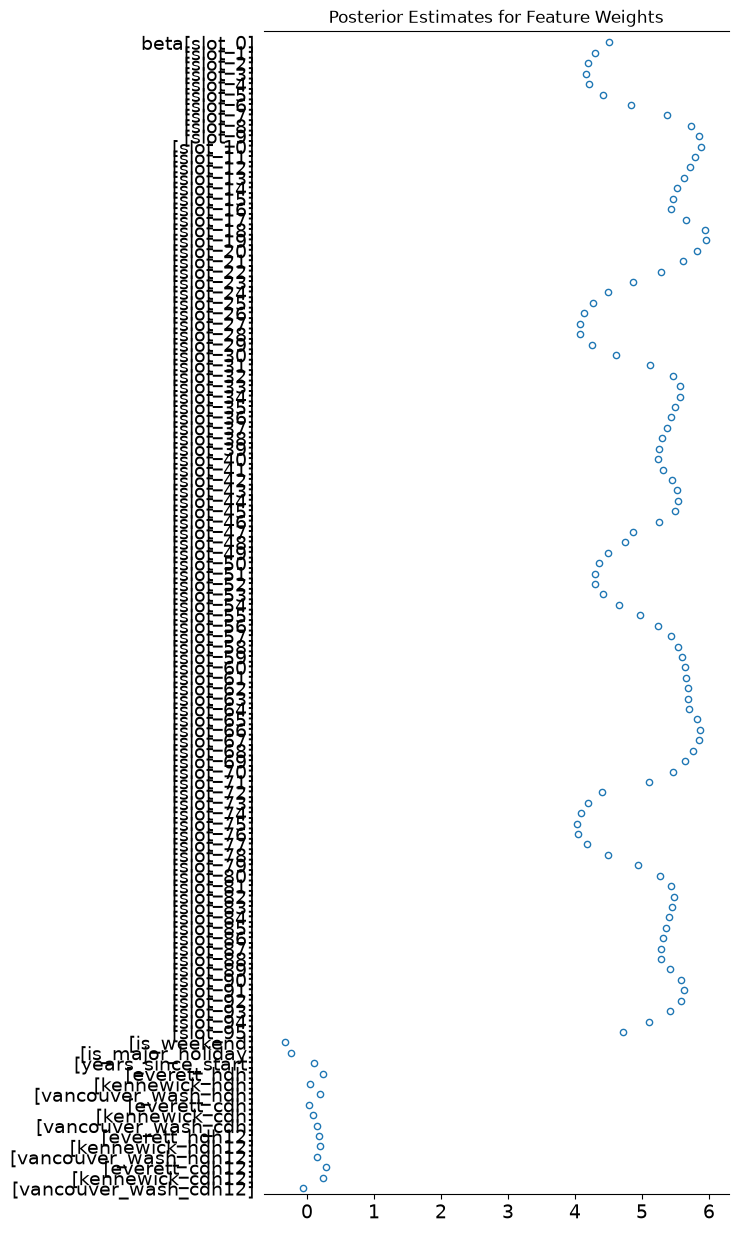

In [67]:
# Plot the posterior distributions for beta weights
az.plot_forest(idata_m2_full, var_names=["beta"], hdi_prob=0.94, combined=True)
plt.title("Posterior Estimates for Feature Weights")
plt.show()

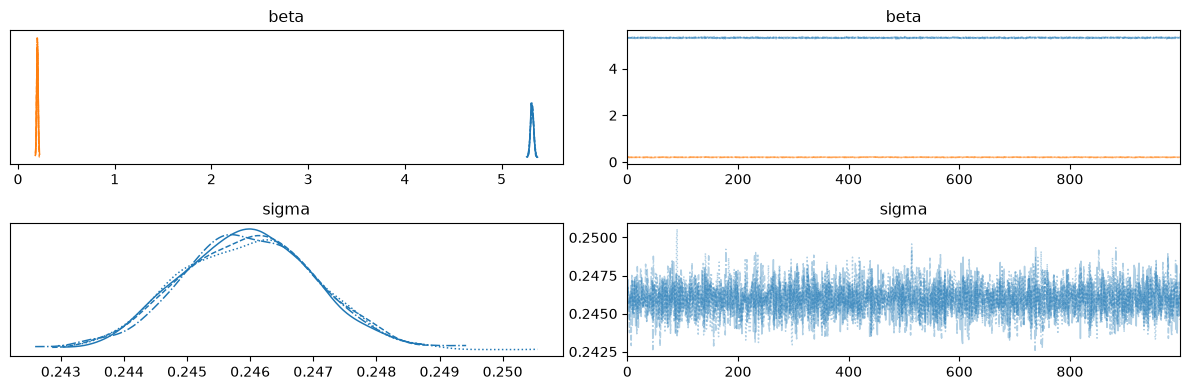

In [68]:
# az.plot_trace(idata_m2_full, var_names=['sigma'])
# plt.show()

# az.plot_trace(idata_m2_full,var_names=['beta'])
# plt.show()
#plot traces
az.plot_trace(idata_m2_full, var_names=["beta", "sigma"],
              coords={"feature": ["slot_41", "kennewick_hdh12"]}) 
plt.tight_layout()
plt.show()

/Users/koonima/DS_playground/pnw-demand-forecast/venv/lib/python3.11/site-packages/arviz/plots/plot_utils.py:270: UserWarning: rcParams['plot.max_subplots'] (40) is smaller than the number of variables to plot (111) in plot_posterior, generating only 40 plots
  warnings.warn(


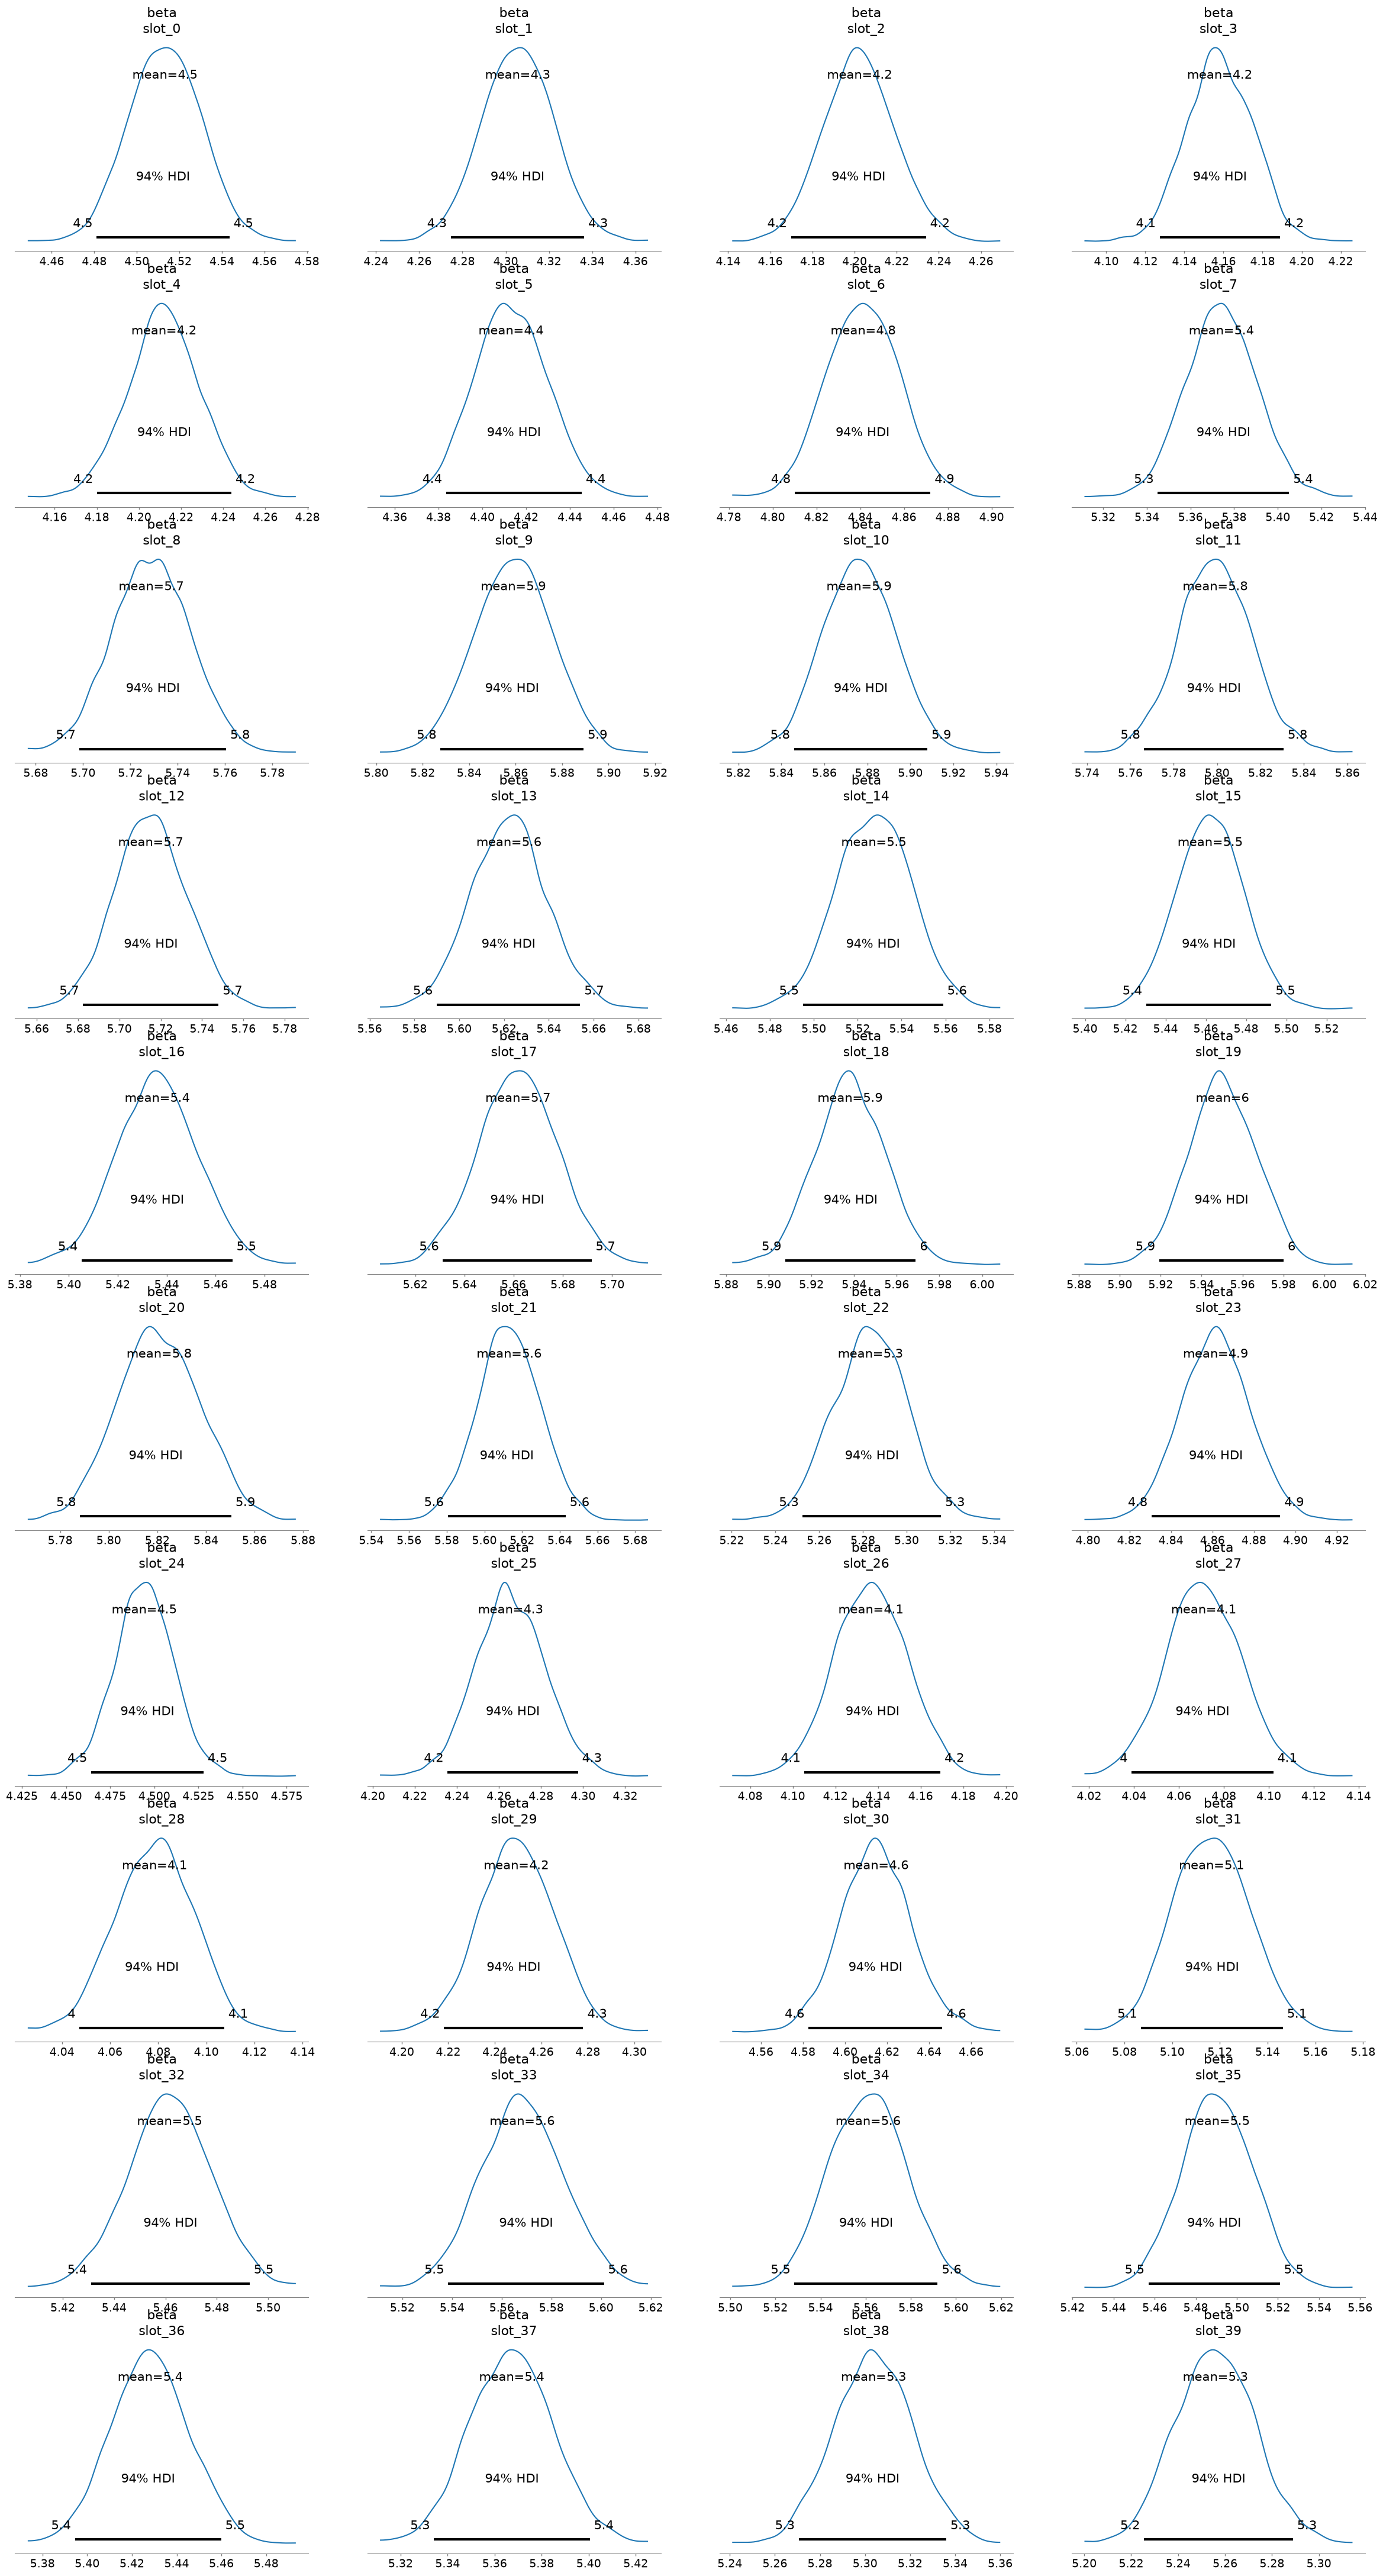

In [69]:
az.plot_posterior(idata_m2_full, var_names=["beta"]) # ref_val adds a vertical reference line
plt.show()

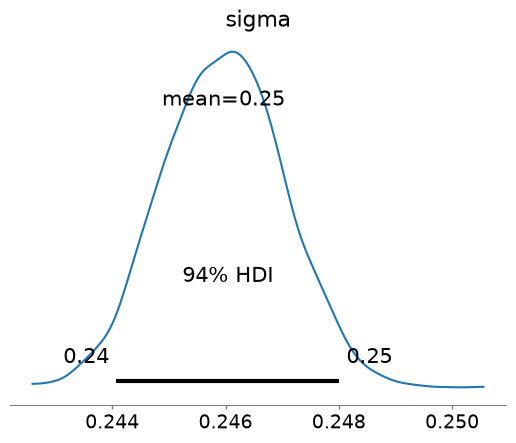

In [70]:
az.plot_posterior(idata_m2_full, var_names=["sigma"]) # ref_val adds a vertical reference line
plt.show()

## Calibration check

In [71]:
#use valid data with the model
#we used PyMC data wrapper and set shape on that so we can reset the data

#build valid 
X_va_full = build_X(valid,ALL_WEATHER)

#check
print(f"shape: {X_va_full.shape}") #8784,111
print(f"same columns: {list(X_va_full.columns)==list(X_full.columns)}")#True


shape: (8784, 111)
same columns: True


In [72]:
with m2_full: #model being used
    pm.set_data({"X": X_va_full.values,
                 "y_obs":np.zeros(len(X_va_full)) #need length correct
                 })

    #posterior predictive
    pp_valid = pm.sample_posterior_predictive(idata_m2_full, var_names=['y'],random_seed = SEED) #predicts demand based on the model and uses the valid data

y_pred = pp_valid.posterior_predictive["y"] * DEMAND_SCALE
print(y_pred.dims, y_pred.shape)

Sampling: [y]


Output()

('chain', 'draw', 'y_dim_0') (4, 1000, 8784)


The posterior predictive sample: for the 4000 posterior draws it computes the `X@beta` for every hour. It then adds random noise of size `sigma`
and useing var_names='y' means we only need the demand predictions

In [73]:
lo = y_pred.quantile(0.05, dim=("chain", "draw")).values #5th percentile per hour
hi = y_pred.quantile(0.95, dim=("chain", "draw")).values #95th percentile per hour 
actual = valid["demand_mwh"].values

inside = (actual >= lo) & (actual <= hi)
print(f"coverage of the 90% interval: {inside.mean():.1%}") 
print(f"average interval width: {np.mean(hi - lo):,.0f} MWh")

coverage of the 90% interval: 91.6%
average interval width: 810 MWh


**91.6% of 2024 hours fall inside the 90% interval**, with an average width of 810 MWh. 
That width is almost exactly what the noise alone predicts: a 90% normal range is ±1.645 x sigma = ±1.645 x 246 ~ ±405, so ~810 wide. The weight uncertainty adds almost nothing, which fits the narrow location totals above.


Overall, that's close to the 90% promised, but it's one number for the whole year, so check where the misses are.

### Where does the interval miss?
An overall 90% can hide offsetting problems: too narrow in some places, too wide in others. Three checks:
1. **Which side** are the misses on? A calibrated model splits its 10% evenly, ~5% above and ~5% below. Lopsided = biased center.
2. **When** are the misses? Coverage by month and by hour of day.
3. **Are misses independent?** The model assumes each hour's error is independent of the last. If errors come in streaks, intervals for a whole day are less trustworthy than the hourly number suggests.

In [74]:
#sides
above = actual > hi #real demand above the interval -> model under-predicted
below = actual < lo #real demand below the interval -> model over-predicted

print(f"above the interval: {above.mean():.1%}, below: {below.mean():.1%}") #calibrated: ~5% each
print(f"interval width: min {np.min(hi - lo):,.0f}, max {np.max(hi - lo):,.0f} MWh") #how much does the width vary

above the interval: 6.5%, below: 2.0%
interval width: min 770, max 861 MWh


So it is looking lopsided

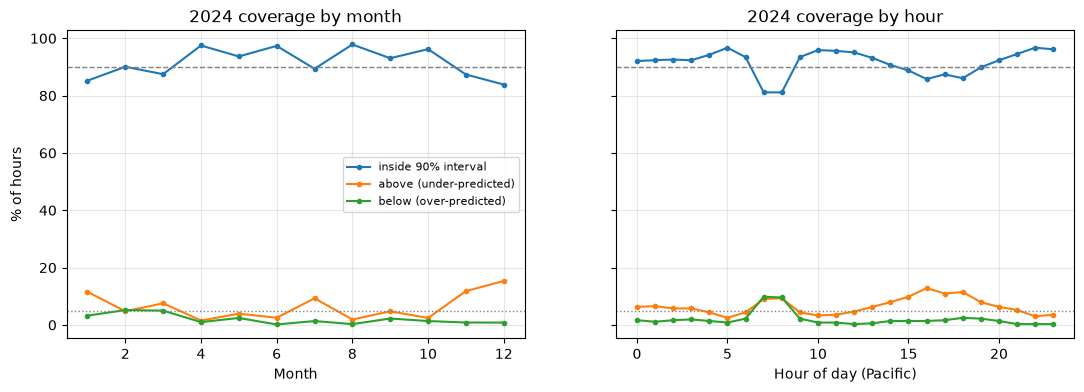

month,1,2,3,4,5,6,7,8,9,10,11,12
inside,85.2,90.1,87.5,97.5,93.7,97.4,89.4,97.8,93.1,96.2,87.4,83.9
above,11.6,4.7,7.5,1.5,3.9,2.5,9.3,1.9,4.7,2.4,11.8,15.3
below,3.2,5.2,5.0,1.0,2.4,0.1,1.3,0.3,2.2,1.3,0.8,0.8


In [75]:
#coverage by month and by hour
cal = pd.DataFrame({
    "inside": inside, "above": above, "below": below,
    "month": valid["month"].values, "hour": valid["hour_pacific"].values,
})

by_month = cal.groupby("month")[["inside", "above", "below"]].mean() * 100
by_hour = cal.groupby("hour")[["inside", "above", "below"]].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axis, tab, xlabel in [(axes[0], by_month, "Month"), (axes[1], by_hour, "Hour of day (Pacific)")]:
    axis.plot(tab.index, tab["inside"], marker="o", markersize=3, label="inside 90% interval")
    axis.plot(tab.index, tab["above"], marker="o", markersize=3, label="above (under-predicted)")
    axis.plot(tab.index, tab["below"], marker="o", markersize=3, label="below (over-predicted)")
    axis.axhline(90, color="gray", linestyle="--", linewidth=1)
    axis.axhline(5, color="gray", linestyle=":", linewidth=1)
    axis.set_xlabel(xlabel)
    axis.grid(alpha=0.3)
    
axes[0].set_ylabel("% of hours")
axes[0].set_title("2024 coverage by month")
axes[1].set_title("2024 coverage by hour")
axes[0].legend(fontsize=8)
plt.show()

by_month.round(1).T

So by hour we under predict and months during winter 
Overall there is month to month dependece, we sort of inferred this in the beginning

In [76]:
#error lengths/streaks
median_pred = y_pred.median(dim=("chain", "draw")).values
resid = pd.Series(actual - median_pred) #valid is in time order with no gaps, so shift(1) = previous hour

print("error correlation with the previous hour:", round(resid.autocorr(1), 2))
print("error correlation with the same hour yesterday:", round(resid.autocorr(24), 2))

error correlation with the previous hour: 0.91
error correlation with the same hour yesterday: 0.47


From the above we get:
- The misses are lopsided: 6.5% above the interval, 2.0% below (calibrated would be ~5% / ~5%). The center is too low, the same under-prediction as the −64 MWh bias, from growth that a straight-line trend fit on 2021–2023 doesn't capture.
- Coverage depends strongly on the month: Dec 83.9%, Jan 85.2%, Nov 87.4%, Mar 87.5%, Jul 89.4% (too narrow) vs Apr 97.5%, Jun 97.4%, Aug 97.8% (too wide). The months that miss are mostly misses *above*: cold snaps and heat waves push demand past the interval (Dec: 15.3% above).
- And on the hour: coverage drops at the morning ramp (7–8 am, both above and below: the *timing* of the ramp is uncertain) and the late-afternoon peak (4–6 pm, mostly above), and is ~92–97% overnight and late evening.
- Yet the width barely changes: 770–861 MWh all year. this is likely because the model has a single `sigma`, so it gives every hour the same uncertainty. Real uncertainty is bigger on winter peaks and ramps and smaller on mild spring nights. The 91.6% overall comes from too-wide intervals in calm months averaging out too-narrow ones in hard months.
- Errors come in streaks: correlation 0.91 with the previous hour and 0.47 with the same hour the day before. When the model is wrong, it's wrong for hours at a time (a cold snap lasts a day, not an hour), so a bad day will tend to miss many hours together.

## So where are we at next steps


The model works -> the Bayesian model matches OLS on the point forecast (2.72% MAPE on 2024), samples cleanly after the slot-level fix, gives per-location heating/cooling effects with uncertainty, and its 90% interval covers 91.6% of 2024 hours overall.

However What we found in the calibration check is: 

- Intervals the same width everywhere at a width 771–853 MWh all year; too narrow in Dec–Jan and at the ramps, too wide in spring/summer. This is from one `sigma` for every hour 
    - what we need to do is let `sigma` vary by season x hour
- the Center is too low. It misses 3x more often above than below with the worst in Nov–Dec. This is likely from the straight-line trend from 2021–2023 
    - what we need to do is add a level that can move over time to adjust as it goes
- Errors come in streaks as we saw that there is a strong hour-to-hour error correlation. We assumed each hour's error was independent and we want to be true 
    - honestly just note for now and be weary but no immediate fix

Addressing the above in order goes like this: 
1. The Varying noise: give a `sigma` per season x hour slot (or season + hour group). Compare coverage by month/hour against this model. Expectation: Dec–Jan and the ramps get wider intervals, spring/summer narrower.
2. THe Moving level: we need to replace the straight-line trend with a level that can drift month to month. Expectation: smaller bias, intervals that widen the further past training you forecast.
3. Test period and scored once: retrain on 2021–2024, forecast Jan 2025 – Aug 2026, report MAPE/bias next to EIA and the GBM, plus interval coverage

## Varying noise -> Noise that varies by season x hour

The calibration check showed intervals that are the same width (~770–860 MWh) everywhere, too narrow in Dec–Jan and at the ramps, too wide in spring/summer. That comes from one model assumption: a single `sigma` for every hour so we will relax this and fix it. 

**Evidence first:** if the noise really differs by season x hour, the OLS errors on the training years should spread more in some slots than others.

one sigma for everything: 245 MWh
per slot: min 183, median 238, max 367 MWh


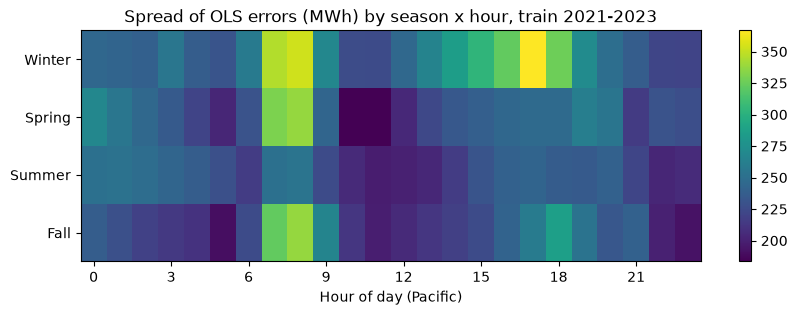

In [77]:
#spread of OLS errors on train
# given by season x hour slot

resid_train = train["demand_mwh"] - ols_final.predict(design(train, "SH", ALL_WEATHER)) #get difference between difference and prediction, OLS final prediction hre

spread = resid_train.groupby([train["season"], train["hour_pacific"]]).std().unstack("season") #get spread of the season and hours to use
spread.columns = ["Winter", "Spring", "Summer", "Fall"]

print(f"one sigma for everything: {resid_train.std():.0f} MWh") #original value 
print(f"per slot: min {spread.min().min():.0f}, median {np.median(spread):.0f}, max {spread.max().max():.0f} MWh") #one per slot

#plot as heatmap to see how season x hours work 
fig, ax = plt.subplots(figsize=(10, 3))

im = ax.imshow(spread.T, aspect="auto", cmap="viridis")
ax.set_yticks(range(4), spread.columns) #4 seasons
ax.set_xticks(range(0, 24, 3)) #hours in a day
ax.set_xlabel("Hour of day (Pacific)")
ax.set_title("Spread of OLS errors (MWh) by season x hour, train 2021-2023")
fig.colorbar(im, ax=ax)

plt.show()

This shows the noise differs a lot by slot:
- from 183 to 367 MWh, while the model uses one value for all of them. 
- The biggest spreads are winter late afternoon/evening (~5 with 367) and the 7–8 am ramp (excluding summer) at ~330–350 
- the smallest are summer and spring middays (~200). That lines up with where the coverage check found the intervals too narrow (Dec–Jan, 7–8 am, 4–6 pm) and too wide (spring/summer).

### The model change
Replace the single `sigma` with **one sigma per season x hour slot**, the same 96 slots used for the demand level. 

Three design choices to make this work:

1. Model `log(sigma)`, not `sigma`. The Noise must be positive and the differences are ratios so this means any value of log(sigma) is allowed and exp() turns it back into a positive sigma. This is mainly easier bookkeeping.
2. Partial pooling-> Each slot's log-sigma comes from a shared distribution which we will call  `log_sigma_typical` (the usual noise) plus `log_sigma_spread` (how much slots differ) and the data estimates the spread. So if the slots really differ then the spread comes out large and each slot follows its own data BUT if not then it shrinks and slots are pulled toward the typical value. This is means it is a hierarchical model and it matters most when a slot has little data
3. Non-centered: the  `log_sigma = typical + spread * z`, with `z ~ Normal(0, 1)` per slot. Writing `log_sigma ~ Normal(typical, spread)` directly creates a "funnel" that when the spread is small then all 96 are forced together and the sampler has to move them as a group (the same problem as the intercept). Sampling `z` keeps them independent.

Our Priors: typical noise `log(0.25) +- 0.5` wide. The spread is `HalfNormal(0.3)`, so slots can differ by roughly +-35% from typical, which leaves room for the OLS table without assuming it.

we will keep this if coverage by month and by hour moves closer to 90% (roughly every month within 85–95%) with overall still ~90%. 

Sampling: [beta, log_sigma_spread, log_sigma_typical, y, z]


simulated 5%-95%: 2,159 to 11,807 MWh
simulated median: 6,974 MWh  (real median 6,438)
share negative: 1.2%


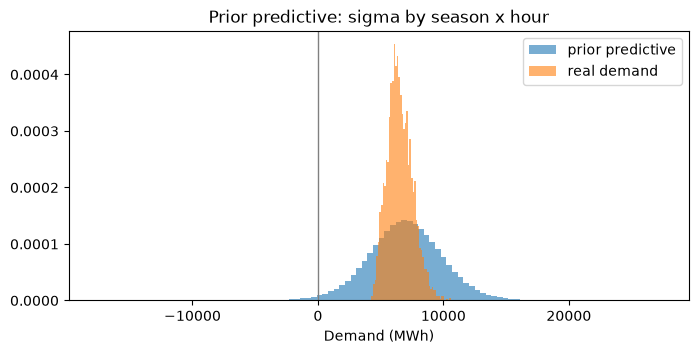

In [78]:
def slot_index(data):
    '''
    Season x hour slot (0-95) for each row, same numbering as the slot_ columns
    '''
    v = (data['season'] * 24 + data['hour_pacific']).values.astype('int64')
    return v


def build_model_vs(X, y, slots, weather_cols):
    '''
    Same as build_model before but sigma varies by season x hour slot 
    '''
    mu_p, sd_p = make_priors(X.columns, weather_cols)

    with pm.Model(coords={"feature": X.columns, "slot": range(96)}) as model:
        X_data = pm.Data("X", X.values)
        y_data = pm.Data("y_obs", y.values)
        s_data = pm.Data("slot_idx", slots) #which slot each row is in, swappable like X

        beta = pm.Normal("beta", mu=mu_p.values, sigma=sd_p.values, dims="feature")

        #noise per slot on the log scale
        #typical level + slot-specific deviation
        log_sigma_typical = pm.Normal("log_sigma_typical", mu=np.log(0.25), sigma=0.5)
        log_sigma_spread = pm.HalfNormal("log_sigma_spread", sigma=0.3)
        z = pm.Normal("z", mu=0, sigma=1, dims="slot")
        sigma = pm.Deterministic("sigma", pm.math.exp(log_sigma_typical + log_sigma_spread * z), dims="slot")

        pm.Normal("y", mu=X_data @ beta, sigma=sigma[s_data], observed=y_data, shape=X_data.shape[0])
    return model


m4 = build_model_vs(X_sub_f, y_sub, slot_index(train.loc[sub.index]), ALL_WEATHER)
prior_m4 = prior_check(m4, "Prior predictive: sigma by season x hour")

In [79]:
idata_m4 = sample(m4)

display(pd.concat([diagnostics(idata_m2, "m2: one sigma"),
                   diagnostics(idata_m4, "m4: sigma by slot")], ignore_index=True))

#check if slots differ
#spread well above 0 = yes
az.summary(idata_m4, var_names=["log_sigma_typical", "log_sigma_spread"])[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "r_hat"]]

sampling time: 101 s


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m2: one sigma,1.01,0,624.0,0,0
1,m4: sigma by slot,1.02,4,340.0,6,0


,mean,sd,hdi_3%,hdi_97%,ess_bulk,r_hat
log_sigma_typical,-1.432,0.019,-1.468,-1.395,2473.0,1.0
log_sigma_spread,0.134,0.020,0.098,0.171,1315.0,1.0


**Subset run:**
- **Slots really differ.** `log_sigma_spread` is 0.134 (94%: 0.10–0.17), clearly above 0, so the data rejects "one sigma for all". On the log scale 0.134 means a typical slot is about +-14% from the typical noise.
- **Borderline diagnostics:** r_hat up to 1.02 on 4 weights, min ESS 340 (6 weights under 400), 0 divergences. That's just short of the rule. The hardest weights are again the weather twins. the extra noise parameters make their credit-splitting a bit harder to sample. Acceptable for a subset test; the full run is the one that matters.
- The prior check is still plausible

### Full fit
Same caching pattern as `m2`: the samples are saved so the ~30+ minute run only happens once.

In [80]:
M4_FULL_PATH = RESULTS / "idata_m4_full.nc"

m4_full = build_model_vs(X_full, y_full, slot_index(train), ALL_WEATHER)

if M4_FULL_PATH.exists():
    idata_m4_full = az.from_netcdf(M4_FULL_PATH)
    print(f"Loaded saved samples from: {M4_FULL_PATH}")
else:
    idata_m4_full = sample(m4_full)
    idata_m4_full.to_netcdf(M4_FULL_PATH)
    print(f"saved samples to: {M4_FULL_PATH}")

pd.concat([diagnostics(idata_m2_full, "m2 full: one sigma"),
           diagnostics(idata_m4_full, "m4 full: sigma by slot")], ignore_index=True)

Loaded saved samples from: ../results/idata_m4_full.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m2 full: one sigma,1.01,0,577.0,0,0
1,m4 full: sigma by slot,1.03,2,280.0,3,0


### Calibration: m2 vs m4
The calibration steps from before go into one function so both models are scored exactly the same way
`new_data` is whatever `pm.set_data` needs for that model and m4 needs `slot_idx`

In [81]:
def calibration(model, idata, new_data, actual, months, hours, name, level=0.90):
    '''
    Posterior predictive on new data -> interval, coverage overall / by month / by hour
    '''
    with model:
        pm.set_data(new_data)
        pp = pm.sample_posterior_predictive(idata, var_names=["y"], random_seed=SEED, progressbar=False)

    y_draws = pp.posterior_predictive["y"] * DEMAND_SCALE
    tail = (1 - level) / 2
    lo = y_draws.quantile(tail, dim=("chain", "draw")).values
    hi = y_draws.quantile(1 - tail, dim=("chain", "draw")).values
    med = y_draws.median(dim=("chain", "draw")).values

    inside = (actual >= lo) & (actual <= hi)
    summary = pd.DataFrame({
        "model": [name],
        "coverage_pct": [100 * inside.mean()],
        "above_pct": [100 * (actual > hi).mean()],
        "below_pct": [100 * (actual < lo).mean()],
        "width_mean": [np.mean(hi - lo)],
        "width_min": [np.min(hi - lo)],
        "width_max": [np.max(hi - lo)],
        "mape_pct": [100 * np.mean(np.abs(med - actual) / actual)],
        "bias_mwh": [np.mean(med - actual)],
    }).round(1)
    by_month = pd.Series(inside, index=months).groupby(level=0).mean() * 100
    by_hour = pd.Series(inside, index=hours).groupby(level=0).mean() * 100
    return {"summary": summary, "by_month": by_month, "by_hour": by_hour, "lo": lo, "hi": hi, "med": med}


actual = valid["demand_mwh"].values
X_va_full = build_X(valid, ALL_WEATHER)
n_va = len(X_va_full)

cal_m2 = calibration(m2_full, idata_m2_full,
                     {"X": X_va_full.values, "y_obs": np.zeros(n_va)},
                     actual, valid["month"].values, valid["hour_pacific"].values, "m2: one sigma")
cal_m4 = calibration(m4_full, idata_m4_full,
                     {"X": X_va_full.values, "y_obs": np.zeros(n_va), "slot_idx": slot_index(valid)},
                     actual, valid["month"].values, valid["hour_pacific"].values, "m4: sigma by slot")

pd.concat([cal_m2["summary"], cal_m4["summary"]], ignore_index=True)

Sampling: [y]


Sampling: [y]


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m2: one sigma,91.6,6.5,2.0,810.1,770.5,860.9,2.7,-63.6
1,m4: sigma by slot,91.9,6.6,1.5,801.5,595.2,1217.1,2.7,-67.1


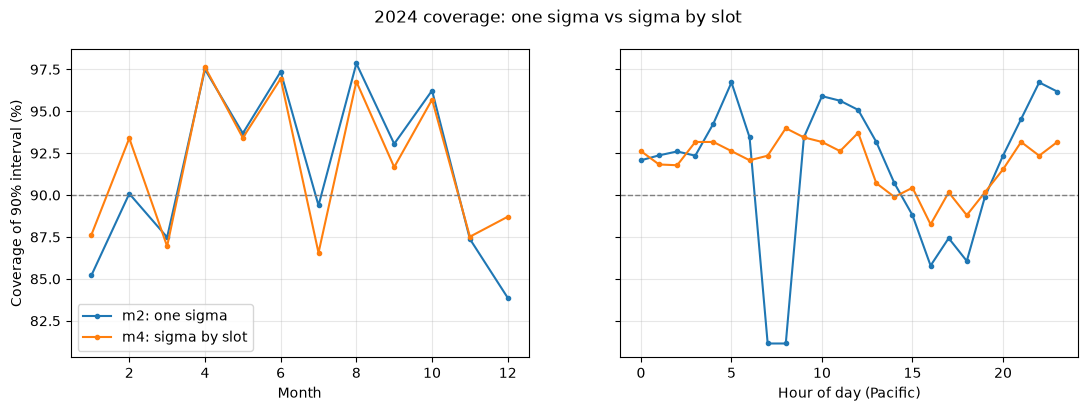

,1,2,3,4,5,6,7,8,9,10,11,12
m2,85.2,90.1,87.5,97.5,93.7,97.4,89.4,97.8,93.1,96.2,87.4,83.9
m4,87.6,93.4,86.9,97.6,93.4,96.9,86.6,96.8,91.7,95.7,87.5,88.7


In [82]:
def plot_coverage(cals, title):
    '''
    Coverage by month and by hour for several calibration results
    '''
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

    for cal in cals:
        name = cal["summary"]["model"].iloc[0]
        axes[0].plot(cal["by_month"].index, cal["by_month"].values, marker="o", markersize=3, label=name)
        axes[1].plot(cal["by_hour"].index, cal["by_hour"].values, marker="o", markersize=3, label=name)

    for axis, xlabel in [(axes[0], "Month"), (axes[1], "Hour of day (Pacific)")]:
        axis.axhline(90, color="gray", linestyle="--", linewidth=1)
        axis.set_xlabel(xlabel)
        axis.grid(alpha=0.3)
        
    axes[0].set_ylabel("Coverage of 90% interval (%)")
    axes[0].legend()
    fig.suptitle(title)
    plt.show()

plot_coverage([cal_m2, cal_m4], "2024 coverage: one sigma vs sigma by slot")
pd.DataFrame({"m2": cal_m2["by_month"], "m4": cal_m4["by_month"]}).round(1).T

The m4 does better when we look per hour and about the same per month

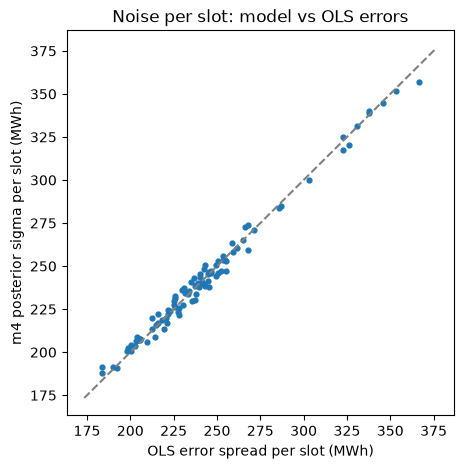

m4 sigma per slot: min 188, max 357 MWh


In [ ]:
# posterior sigma per slot vs the OLS spread table

sigma_m4 = idata_m4_full.posterior["sigma"].mean(dim=("chain", "draw")).values * DEMAND_SCALE
ols_spread = resid_train.groupby(slot_index(train)).std().values  #same slot order (0-95)

fig, ax = plt.subplots(figsize=(5, 5))

#points of spread
ax.scatter(ols_spread, sigma_m4, s=12)

#get min and max for line
lims = [min(ols_spread.min(), sigma_m4.min()) - 10, max(ols_spread.max(), sigma_m4.max()) + 10]
ax.plot(lims, lims, color="gray", linestyle="--")

ax.set_xlabel("OLS error spread per slot (MWh)")
ax.set_ylabel("m4 posterior sigma per slot (MWh)")
ax.set_title("Noise per slot: model vs OLS errors")
plt.show()

print(f"m4 sigma per slot: min {sigma_m4.min():.0f}, max {sigma_m4.max():.0f} MWh")

What changed with sigma by slot (full fit, scored on 2024):
- Diagnostics give 0 divergences; r_hat up to 1.03 on 2 weights and min ESS 280 (3 weights under 400). Close to but misses level we want. The simple fix is running more draws (e.g. 2,000)
- It learned the right noise per slot with posterior sigma ranges 188–357 MWh and tracks the OLS error spread closely. With all of train, each slot has ~270 hours, so the pooling barely pulls them together 
- Intervals now change width: 595–1,217 MWh instead of 770–861. Overall coverage is about the same (91.9% vs 91.6%), and the point forecast is unchanged (2.7% MAPE).
- By hour, fixed: coverage at 7–8 am went from ~81–82% to ~92–94% (intervals there widened to ~1,030–1,060 MWh), the 4–6 pm peak from ~86–88% to ~89–90%, and midday/overnight slots got narrower without losing coverage. Every hour is now within ~89–94%.
- By month, only partly: Dec 83.9 to 88.7%, Jan 85.2 to 87.6%, Feb 90.1 to 93.4%, but Jul 89.4 to 86.6% and Mar/Nov unchanged (~87%). The remaining monthly misses are mostly above the interval (6.6% above vs 1.5% below overall) this is because the center is too low, which sigma can't fix and is next step

We will keep this sigma assignment

## Moving level -> A level that can move over time 

The other calibration problem: 
- the misses are lopsided (more above than below), because the center is too low. The straight-line trend fit on 2021–2023 doesn't keep up with 2024. And we saw demand stepping up in 2025–26.

So instead of a fixed straight line we will let the baseline level change month to month this looks like:

```
demand = weather/calendar part (X @ beta) + level[month] + noise
```

Where we have: 
- In training months, `level` is learned from the data.
- In forecast months the model has no data, so `level` keeps evolving the way it evolved in training. The further ahead, the less certain, so intervals should widen with forecast horizon. That's being honest about not knowing where the level has moved.


The thing we need to do now is figure out how `level` is allowed to move. 
We will try a few different ways and compare to the model above and we will keep a moving level only if it samples cleanly (r_hat ≤ 1.01, no divergences) and improves 2024 bias without hurting coverage.

-Start with a random walk so the level wanders
We will try to improve upon this each time with what we see but it is likely to be the random walk + something to help it

In [84]:
#this is a helper cell
#build functions to help get correct months
N_MONTHS = 48  #Jan 2021 - Dec 2024: training months 0-35, validation months 36-47

#to get months need this since level is moving
def month_index(data):
    '''
    Months since Jan 2021 (Pacific). The 8 hours of Dec 31 2020 Pacific go to month 0
    '''
    p = data["period_utc"].dt.tz_convert("America/Los_Angeles")
    return np.maximum((p.dt.year - 2021) * 12 + p.dt.month - 1, 0).values.astype("int64")

#way to save runs and load then
def sample_cached(model, path):
    '''
    Sample once and save; load next time (delete the file to re-sample)
    '''
    if path.exists():
        print(f"loaded {path.name}")
        return az.from_netcdf(path)
    idata = sample(model)
    idata.to_netcdf(path)
    return idata


#get data with these month indexes
m_sub = month_index(train.loc[sub.index])
m_va = month_index(valid)
s_sub = slot_index(train.loc[sub.index])
s_va = slot_index(valid)
X_va_f = build_X(valid, ALL_WEATHER)   #validation matrix in the m2/m4 layout

print("train months:", m_sub.min(), "-", m_sub.max(), " valid months:", m_va.min(), "-", m_va.max())   #expect 0-35, 36-47

train months: 0 - 35  valid months: 36 - 47


### The model: m4 + a monthly level
`build_model_level` is `m4` with one addition, `+ level[month]` in the mean. This is a helper to build the model we want with a level function

The level moves since it is passed in as a small function (`level_fn`), so each try below only has to write that part. 

We will want to look at results so going to write two more helpers to plot then basically a helper that does it all these are:
- `plot_level` (level by month with its 94% band, forecast months marked)  
- `level_experiment` (build -> sample then saved to `results/` -> diagnostics -> level plot -> 2024 calibration) the pipeline 

Priors are the same as `make_priors` (slot levels ~ Normal(7, 2), everything else ~ Normal(0, 0.5)), set directly here because some tries drop or add columns.

In [85]:
#function to build this new trend
#the level part is passed in as a function:
#each try below adds its own level function, this stays the same

def build_model_level(X, y, slots, months, level_fn):
    '''
    m4 + level[month]; level_fn builds the level inside the model and returns it (length N_MONTHS)
    '''
    #same priors as make_priors
    #slot levels ~ Normal(7, 2), everything else ~ Normal(0, 0.5)
    #set here directly because the walk drops years_since_start and month-of-year columns are new
    mu_p = pd.Series(0.0, index=X.columns)
    sd_p = pd.Series(0.5, index=X.columns)
    is_slot = X.columns.str.startswith("slot_")
    mu_p[is_slot] = 7.0
    sd_p[is_slot] = 2.0

    coords = {"feature": X.columns, "slot": range(96), "month": range(N_MONTHS), "step": range(1, N_MONTHS)}
    with pm.Model(coords=coords) as model:
        X_data = pm.Data("X", X.values)
        y_data = pm.Data("y_obs", y.values)
        s_data = pm.Data("slot_idx", slots)
        m_data = pm.Data("month_idx", months)

        beta = pm.Normal("beta", mu=mu_p.values, sigma=sd_p.values, dims="feature")
        level = pm.Deterministic("level", level_fn(), dims="month")

        log_sigma_typical = pm.Normal("log_sigma_typical", mu=np.log(0.25), sigma=0.5)
        log_sigma_spread = pm.HalfNormal("log_sigma_spread", sigma=0.3)
        z = pm.Normal("z", mu=0, sigma=1, dims="slot")
        sigma = pm.Deterministic("sigma", pm.math.exp(log_sigma_typical + log_sigma_spread * z), dims="slot")

        pm.Normal("y", mu=X_data @ beta + level[m_data], sigma=sigma[s_data],
                  observed=y_data, shape=X_data.shape[0])
    return model


def plot_level(idata, title):
    '''
    Level by month (MWh): median and 94% band, with the start of the forecast marked
    '''
    lv = idata.posterior["level"] * DEMAND_SCALE
    med = lv.median(dim=("chain", "draw")).values
    lo = lv.quantile(0.03, dim=("chain", "draw")).values
    hi = lv.quantile(0.97, dim=("chain", "draw")).values

    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.fill_between(range(N_MONTHS), lo, hi, alpha=0.3)
    ax.plot(range(N_MONTHS), med, marker="o", markersize=3)
    ax.axvline(35.5, color="gray", linestyle="--", linewidth=1)
    ax.text(36, ax.get_ylim()[1], " forecast (2024)", va="top", fontsize=8)
    ax.set_xlabel("Months since Jan 2021")
    ax.set_ylabel("Level (MWh)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    plt.show()


def level_experiment(level_fn, X_tr_k, X_va_k, name):
    '''
    Build -> sample (cached) -> diagnostics -> level plot -> 2024 calibration
    '''
    model = build_model_level(X_tr_k, y_sub, s_sub, m_sub, level_fn)
    idata_k = sample_cached(model, RESULTS / f"idata_{name.split(':')[0]}_sub.nc")
    display(diagnostics(idata_k, name))
    plot_level(idata_k, f"{name}: level by month")
    cal = calibration(model, idata_k,
                      {"X": X_va_k.values, "y_obs": np.zeros(len(X_va_k)), "slot_idx": s_va, "month_idx": m_va},
                      valid["demand_mwh"].values, valid["month"].values, valid["hour_pacific"].values, name)
    return idata_k, cal

**Baseline to beat:** `m4` on the same subset, scored the same way.

In [86]:
cal_m4_sub = calibration(m4, idata_m4,
                         {"X": X_va_f.values, "y_obs": np.zeros(len(X_va_f)), "slot_idx": s_va},
                         valid["demand_mwh"].values, valid["month"].values, valid["hour_pacific"].values,
                         "m4 subset: straight-line trend")
cal_m4_sub["summary"]

Sampling: [y]


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m4 subset: straight-line trend,91.0,7.3,1.7,810.1,632.9,1027.2,2.8,-73.4


### Try 1: random walk
this is first as it's the simplest way to say "the level can move, and changes stick", which matches what 2025–26 looked like (steps up that stayed).


we do this by having each month start where the last one ended, then moves:
```
level[m] = level[m-1] + drift + tau * z[m]
```
- `drift` = average change per month (it takes over from the straight-line slope, so `years_since_start` comes out of X)
- `tau` = size of the random monthly moves, learned from the data
- `level[0] = 0` anchors the walk so it can't trade with the slot levels as a whole 
- written as `cumsum` of the steps, non-centered (`tau * z`) like `sigma` 

Sampling: [beta, drift, log_sigma_spread, log_sigma_typical, tau, y, z, z_step]


simulated 5%-95%: 1,948 to 12,176 MWh
simulated median: 7,055 MWh  (real median 6,438)
share negative: 1.4%


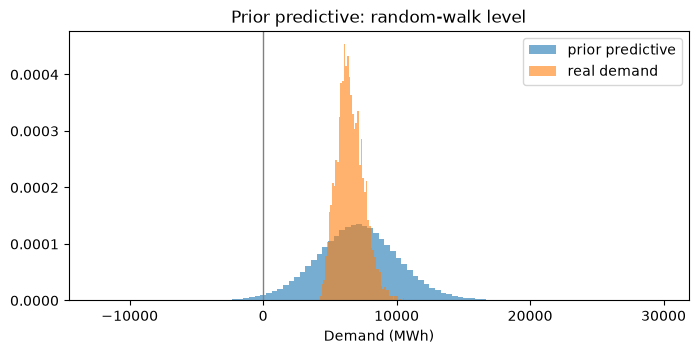

loaded idata_m5a_sub.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m5a: walk,1.08,72,39.0,72,104


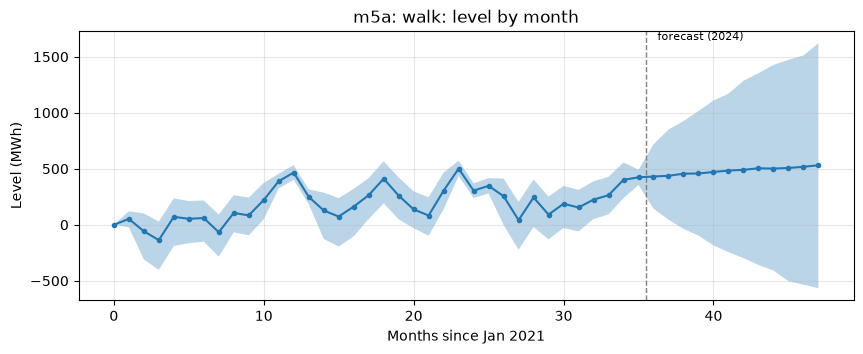

Sampling: [y]


,mean,sd,hdi_3%,hdi_97%
drift,0.009,0.021,-0.028,0.052
tau,0.144,0.024,0.103,0.188


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m5a: walk,98.1,1.2,0.7,1502.3,734.4,2184.6,2.9,36.5


In [ ]:
def level_walk(): #random walk
    '''
    Random walk with drift, anchored at 0 in month 0
    '''
    drift = pm.Normal("drift", 0, 0.05) #average change per month (thousands of MWh), +-50 MWh
    tau = pm.HalfNormal("tau", 0.1)  #size of the random monthly moves
    z = pm.Normal("z_step", 0, 1, dims="step")
    return pm.math.concatenate([[0.0], pm.math.cumsum(drift + tau * z)]) #zero and it accumulates


#update data
X_walk = X_sub_f.drop(columns="years_since_start") #the walk's drift replaces the straight-line trend
X_walk_va = X_va_f.drop(columns="years_since_start")

#build the model 
m5a = build_model_level(X_walk, y_sub, s_sub, m_sub, level_walk)

#check prior 
prior_m5a = prior_check(m5a, "Prior predictive: random-walk level")

#run experiment
idata_m5a, cal_m5a = level_experiment(level_walk, X_walk, X_walk_va, "m5a: walk")
display(az.summary(idata_m5a, var_names=["drift", "tau"])[["mean", "sd", "hdi_3%", "hdi_97%"]])
cal_m5a["summary"]

Well..
- Sampling broke with 104 divergences, r_hat 1.08, ESS as low as 39 so ineffecient and does poor with converging
- The forecast intervals blew up: 1,500 MWh wide on average (up to 2,185 by December), covering 98% of hours. Honest about its uncertainty, but far too wide to be useful.
- The level climbs every Nov–Jan and drops in spring, the same shape every year. The walk is soaking up a something likely a within-season* pattern the 4-season slots can't see (December isn't the same as February). To follow that, it needs big monthly steps (`tau` ≈ 144 MWh/month), and big steps pile up into huge forecast uncertainty.

Based on the level plot we will add a pattern that repeats every year that shouldn't be the walk's job. A 0/1 column per month of the year can explain it directly. Then the walk only has to explain real drift not the months issues

### Try 2: walk + month-of-year columns

**Why:** Try 1's level was mostly a repeating yearly hump.

**What changes:** a new helper, `add_moy` 
- this adds 8 month-of-year 0/1 columns to X. 
- The first month of each season (Dec, Mar, Jun, Sep) is left out as the reference, because the season slots already set each season's level
- the columns only say "January is this much different from December". 
- The walk itself is unchanged.

Check first with OLS. 
- do the new columns change the straight-line trend or the fit on their own? If they did, they'd be confusing the trend rather than just explaining the seasonal pattern.

In [88]:
MOY = [1, 2, 4, 5, 7, 8, 10, 11]   #month-of-year columns; Dec, Mar, Jun, Sep are the references

def add_moy(X, data):
    '''
    Month-of-year 0/1 columns (within-season differences the 4-season slots can't see)
    '''
    X = X.copy()
    for m in MOY:
        X[f"moy_{m}"] = (data.loc[X.index, "month"] == m).astype(float)
    return X


#OLS: does th adding month-of-year change the straight-line trend
for name, (A, B) in {"SH": (X_trs, X_vas), "SH + month-of-year": (add_moy(X_trs, train), add_moy(X_vas, valid))}.items():

    o = LinearRegression(fit_intercept=False).fit(A, y_trs)
    p = o.predict(B) * DEMAND_SCALE

    trend = pd.Series(o.coef_, index=A.columns)["years_since_start"] * DEMAND_SCALE
    
    print(f"{name:20s} trend {trend:5.0f} MWh/yr   MAPE {100 * mean_absolute_percentage_error(valid['demand_mwh'], p):.2f}%   "
          f"bias {np.mean(p - valid['demand_mwh']):6.1f}")

SH                   trend    97 MWh/yr   MAPE 2.72%   bias  -63.3
SH + month-of-year   trend    91 MWh/yr   MAPE 2.74%   bias  -75.7


Month-of-year barely moves the trend (97 → 91 MWh/yr) or the OLS fit, so they're safe to add. Same walk, new X:

loaded idata_m5b_sub.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m5b: walk + month-of-year,1.03,48,167.0,80,263


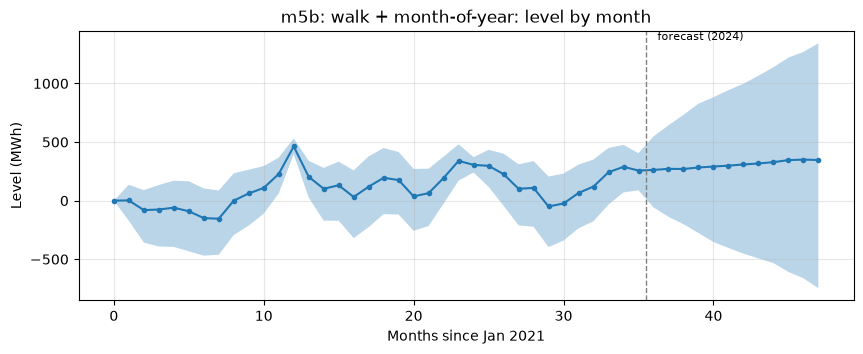

Sampling: [y]


,mean,sd,hdi_3%,hdi_97%
drift,0.006,0.021,-0.033,0.045
tau,0.128,0.027,0.081,0.178


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m5b: walk + month-of-year,96.8,2.9,0.3,1437.4,754.3,2062.0,2.9,-57.2


In [89]:
X_walk_moy = add_moy(X_walk, train)
X_walk_moy_va = add_moy(X_walk_va, valid)

idata_m5b, cal_m5b = level_experiment(level_walk, X_walk_moy, X_walk_moy_va, "m5b: walk + month-of-year")
display(az.summary(idata_m5b, var_names=["drift", "tau"])[["mean", "sd", "hdi_3%", "hdi_97%"]])
cal_m5b["summary"]

- `tau` only dropped to ~128 MWh/month from ~144 and intervals are still ~1,440 MWh wide, 
- sampling got worse 
- The level plot still has winter bumps, but they're ifferent sizes every winter 
- The month-of-year columns took the average winter difference and what's seem like surprises, e.g. a winter colder than the weather terms fully explain. 
- A random walk can only explain a surprise as a permanent shift so the level jumps and stays. So the model concludes "the level jumps a lot" and forecasts huge uncertainty again 

This means we need to give the model a second way to explain a surprise a temporary bump that doesn't carry into the next month. Then the walk only has to handle the changes that last.

### Try 3: slow trend + one-off monthly shocks
Why: Try 2's walk had only permanent change.

What changes here: a new level function that splits the level in two:
```
level[m] = trend[m] + shock_sd * z_shock[m]
```
- `trend` = the walk from before, but with a tighter prior on its steps (`tau ~ HalfNormal(0.03)`) for changes that last
- `shock_sd * z_shock` = an independent bump each month, gone the next, for changes that don't last
- The data decides the split through `tau` vs `shock_sd`. In the forecast, the trend continues and future shocks are new random draws centered at 0.


loaded idata_m5c_sub.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m5c: slow trend + shocks,1.03,96,179.0,96,298


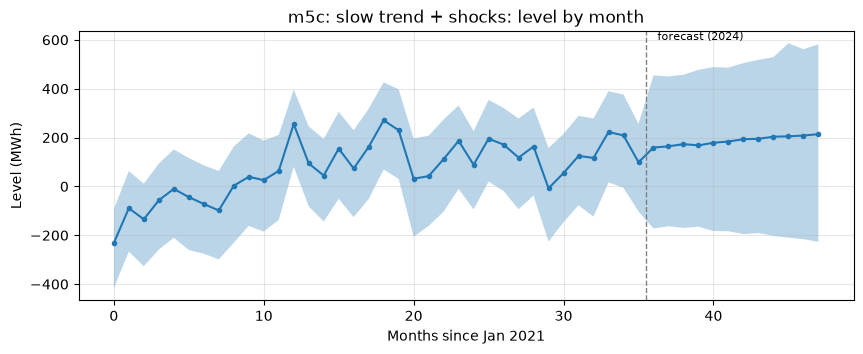

Sampling: [y]


,mean,sd,hdi_3%,hdi_97%
drift,0.004,0.005,-0.008,0.014
tau,0.023,0.014,0.000,0.047
shock_sd,0.113,0.025,0.066,0.158


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m5c: slow trend + shocks,91.4,8.1,0.5,922.7,725.0,1256.4,3.2,-144.3


In [90]:
def level_trend_shock(): #random walk + months variation
    '''
    Slow random-walk trend (lasting changes) + independent monthly shocks (temporary)
    '''

    drift = pm.Normal("drift", 0, 0.05)
    tau = pm.HalfNormal("tau", 0.03) #slow trend: small steps
    z = pm.Normal("z_step", 0, 1, dims="step")

    trend = pm.Deterministic("trend", pm.math.concatenate([[0.0], pm.math.cumsum(drift + tau * z)]), dims="month")

    shock_sd = pm.HalfNormal("shock_sd", 0.2) #size of one-off monthly surprises
    z_shock = pm.Normal("z_shock", 0, 1, dims="month")
    
    return trend + shock_sd * z_shock


idata_m5c, cal_m5c = level_experiment(level_trend_shock, X_walk_moy, X_walk_moy_va, "m5c: slow trend + shocks")
display(az.summary(idata_m5c, var_names=["drift", "tau", "shock_sd"])[["mean", "sd", "hdi_3%", "hdi_97%"]])
cal_m5c["summary"]

- **The data puts almost everything in the temporary shocks:** `shock_sd` ~ 113 MWh/month while the trend's step size `tau` sits right against zero.
- In 2021–2023 there's no lasting drift beyond a straight line and the month-to-month wiggles are temporary.
- Coverage by month is the most even so far 
- sampling is bad (298 divergences) and `tau` near zero is a funnel.
- the forecast is too low with bias −144 MWh and MAPE 3.2%. The trend's drift is only ~50 MWh/yr. The late-2023 months ran above the trend, the model labelled that "temporary", and its 2024 forecast fell back toward the trend. But 2024 stayed high.

What we learn is that the truth for late 2023 looks like it's in between permanent and gone-next-month since we have done both. So we can try to let deviations fade gradually at a rate the data estimates since not everything jumps and ends but jumps and comes down with time. 

### Try 4: deviations that fade 
**Why:** Try 1–2 assumed changes are permanent, Try 3 that they vanish next month, and late 2023 looked like neither.

**What changes:** a new level function. The straight-line trend goes back into X (`years_since_start` kept), and the level becomes a deviation from that line:

```
dev[m] = rho * dev[m-1] + new shock
```

- `rho` = how much of last month's deviation carries over: 0 means one-off shocks, 1 means a random walk, 0.9 means ~10% fades each month. Estimated from the data (prior `Beta(2, 2)`, anywhere in 0–1).
- In the forecast, the last deviation fades back toward the line while new shocks are added.

loaded idata_m5d_sub.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m5d: AR(1) deviation,1.12,98,25.0,97,0


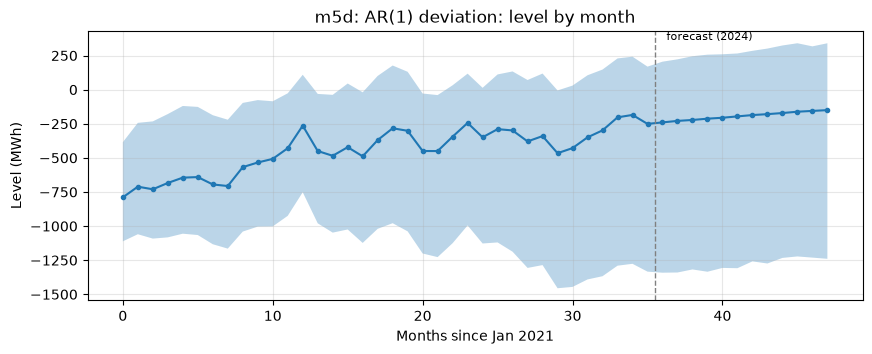

Sampling: [y]


,mean,sd,hdi_3%,hdi_97%
rho,0.892,0.106,0.676,0.999
dev_sd,0.108,0.021,0.072,0.148


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m5d: AR(1) deviation,96.9,2.8,0.4,1202.7,688.8,1615.3,3.0,-118.7


In [91]:
def level_ar():
    '''
    AR(1) deviation from the straight-line trend in X
    '''
    rho = pm.Beta("rho", 2, 2) #0 = shocks vanish next month, 1 = permanent
    dev_sd = pm.HalfNormal("dev_sd", 0.2)
    
    return pm.AR("dev", rho=[rho], sigma=dev_sd, init_dist=pm.Normal.dist(0, 0.2),
                 constant=False, steps=N_MONTHS - 1, dims="month")


X_moy = add_moy(X_sub_f, train) #straight-line trend + month-of-year
X_moy_va = add_moy(X_va_f, valid)

idata_m5d, cal_m5d = level_experiment(level_ar, X_moy, X_moy_va, "m5d: AR(1) deviation")
display(az.summary(idata_m5d, var_names=["rho", "dev_sd"])[["mean", "sd", "hdi_3%", "hdi_97%"]])
cal_m5d["summary"]

- `rho` ~ 0.89 so deviations would fade slowly as suspected.
- It fails differently since the deviation has no anchor there is nothing keeps it from averaging zero, so it competes with the slot levels and the trend for the same job. The level plot drifts from about −790 to −130 MWh across the months.
- Sampling collapses but with poor convergence with r_hat 1.12 and ESS as low as 25, The intervals balloon, and bias is −119 MWh.

Okay so we are seeing the straight line is a good fit but lets try one more. 
We could add an anchor but we are already seeing the sampling is struggling so instead lets go back to what Try 3's posterior said: `tau` ~ 0 means the data finds no lasting drift beyond a straight line. 
So the simplest model the data supports is a straight line plus temporary monthly shocks. Dropping the near-zero trend walk also removes the funnel that broke Try 3's sampler.

### Try 5: straight-line trend + one-off monthly shocks
**Why:** Try 3's `tau` ~ 0, and Try 4 showed adding persistence without an anchor doesn't work.

**What changes:** a new level function with only the temporary shocks. Growth comes from the straight-line trend in X (same `X_moy` as Try 4). It's Try 3 with the slow walk replaced by the straight line.

loaded idata_m5e_sub.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m5e: trend + shocks,1.01,0,487.0,0,0


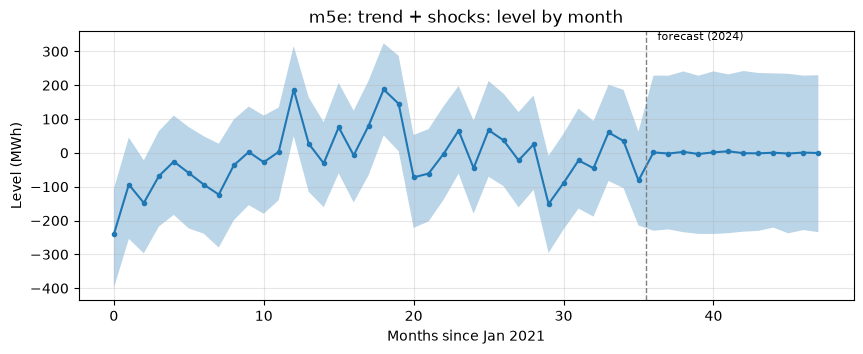

Sampling: [y]


straight-line trend: 60 MWh/yr (OLS: 97)


,mean,sd,hdi_3%,hdi_97%
shock_sd,0.121,0.023,0.083,0.162


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m5e: trend + shocks,91.6,7.7,0.8,886.8,687.7,1228.2,3.0,-120.4


In [92]:
def level_shock():
    '''
    Independent monthly shocks only; the trend is the straight line in X
    '''
    shock_sd = pm.HalfNormal("shock_sd", 0.2)
    z_shock = pm.Normal("z_shock", 0, 1, dims="month")

    return shock_sd * z_shock


idata_m5e, cal_m5e = level_experiment(level_shock, X_moy, X_moy_va, "m5e: trend + shocks")
trend_m5e = float(idata_m5e.posterior["beta"].sel(feature="years_since_start").mean()) * DEMAND_SCALE

print(f"straight-line trend: {trend_m5e:.0f} MWh/yr (OLS: {ols_ref['years_since_start']:.0f})")

display(az.summary(idata_m5e, var_names=["shock_sd"])[["mean", "sd", "hdi_3%", "hdi_97%"]])
cal_m5e["summary"]

- Yay it samples cleanly with r_hat 1.01, min ESS 487, and 0 divergences. Coverage is fine
- results got worse with bias at −120 MWh vs −73 for `m4`, and MAPE 3.0% vs 2.8%. The straight-line trend dropped from 97 to 60 MWh/yr
- The month-of-year columns aren't the cause (OLS check: 97 -> 91) so likely that the shocks quietly took over part of the slope.
    - the 2021 shocks come out mostly negative and the 2022 ones mostly positive so the model can't tell "growth" from "a run of positive surprises". When forecasting, new shocks average zero, so the forecast falls behind the growth.

every way of adding a monthly level has now either broken the sampler or taken over part of the trend. Side by side:

### All five against the baseline

,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,m4 subset: straight-line trend,1.02,4,340.0,6,0
1,m5a: walk,1.08,72,39.0,72,104
2,m5b: walk + month-of-year,1.03,48,167.0,80,263
3,m5c: slow trend + shocks,1.03,96,179.0,96,298
4,m5d: AR(1) deviation,1.12,98,25.0,97,0
5,m5e: trend + shocks,1.01,0,487.0,0,0


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,m4 subset: straight-line trend,91.0,7.3,1.7,810.1,632.9,1027.2,2.8,-73.4
1,m5a: walk,98.1,1.2,0.7,1502.3,734.4,2184.6,2.9,36.5
2,m5b: walk + month-of-year,96.8,2.9,0.3,1437.4,754.3,2062.0,2.9,-57.2
3,m5c: slow trend + shocks,91.4,8.1,0.5,922.7,725.0,1256.4,3.2,-144.3
4,m5d: AR(1) deviation,96.9,2.8,0.4,1202.7,688.8,1615.3,3.0,-118.7
5,m5e: trend + shocks,91.6,7.7,0.8,886.8,687.7,1228.2,3.0,-120.4


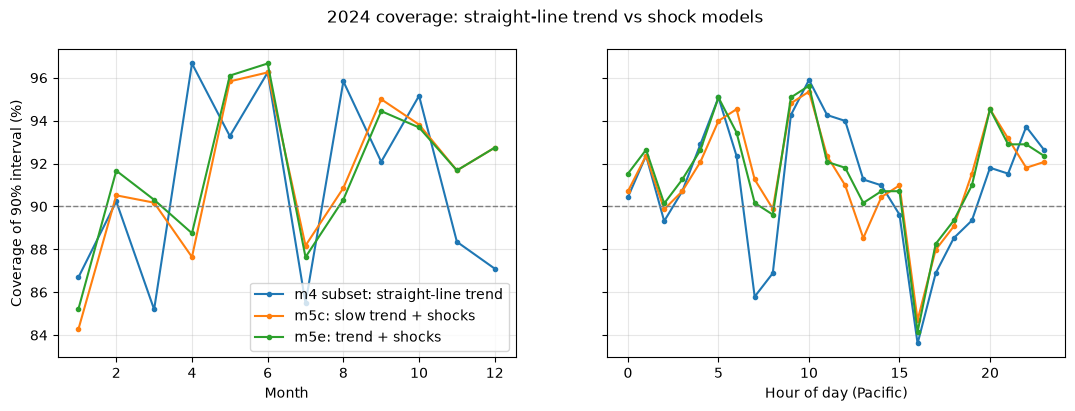

In [93]:
level_runs = {"m5a: walk": idata_m5a, "m5b: walk + month-of-year": idata_m5b,
              "m5c: slow trend + shocks": idata_m5c, "m5d: AR(1) deviation": idata_m5d, "m5e: trend + shocks": idata_m5e}

level_cals = [cal_m4_sub, cal_m5a, cal_m5b, cal_m5c, cal_m5d, cal_m5e]

display(pd.concat([diagnostics(idata_m4, "m4 subset: straight-line trend")] +
                  [diagnostics(v, k) for k, v in level_runs.items()], ignore_index=True))

display(pd.concat([c["summary"] for c in level_cals], ignore_index=True))
plot_coverage([cal_m4_sub, cal_m5c, cal_m5e], "2024 coverage: straight-line trend vs shock models")

## Decision for no moving level and just keep `m4`
Against the rule (samples cleanly **and** improves 2024 bias without hurting coverage), none of the five qualifies:

| try (in order) | samples cleanly? | 2024 bias vs m4 (−73) | what we saw |
|---|---|---|---|
| m5a walk | no (104 div) | +37 (wanders) | absorbed seasonality → huge intervals |
| m5b walk + month-of-year | no (263 div) | −57 | one-off surprises treated as permanent |
| m5c slow trend + shocks | no (298 div) | −144 | trend ≈ 0, recent rise called "temporary" |
| m5d AR(1) | no (ESS 25) | −119 | no anchor, competes with slots and trend |
| m5e trend + shocks | yes | −120 | shocks steal part of the trend |


From this we found:
- With three training years, the data can't separate "trend", "lasting drift" and "one-off monthly surprises". Every extra monthly layer either breaks the sampler or takes over part of the trend. The straight line is the most the data supports for 2021–2023. 
    -possible fix is more training data or some other parameters to help out
- The monthly surprises are real and sizeable at about 110–120 MWh per month (`shock_sd`) on top of the hourly noise. That's points to that even a perfect weather model would be off by roughly that much in a given month
- The level shifts seen in 2025–26 can't be learned from 2021–2023. Detecting them needs liekly needs recent demand as it comes in. 
    - updating the level from yesterday's actual demand
    - This is bayesian in nature as it updates new data as we get more and would be the next big implementation step 

WE will use `m4`, 
- with 96 slot levels, 
- a straight-line trend, 
- 12 weather columns, 
- and sigma by slot. 

Remaining known gaps: under-prediction from faster growth (−67 MWh on 2024), hour-to-hour error streaks, and borderline ESS on a few weather weights.

## Test period -> scored once
Everything so far was chosen on 2024 (validation). The test period, Jan 2025 – Aug 2026, hasn't been touched. This is the one honest score.

**What gets scored:** `m4` exactly as chosen (96 slot levels, straight-line trend, 12 weather columns, sigma by slot), retrained on 2021–2024 (train + valid) so it learns from the most recent year, the same as notebook 04 did for the GBM. It runs with 2,000 draws instead of 1,000, since the full `m4` fit was just short of the ESS rule on a few weather weights.

Compared against notebook 04's saved test predictions (`predictions_test`): EIA's day-ahead forecast, the GBM, linear regression and same-hour-last-week, scored on the same hours (where EIA has a forecast).

What to expect: notebook 04 found demand stepped up twice in the test period (through 2025, then again around Dec 2025). The above experiments showed this model can't anticipate that. So expect under-prediction that grows over time, like the GBM. 

The new question is what the intervals do... does coverage hold up, or does it collapse once the level shifts?

In [ ]:
#retrain data: 2021-2024
trainval = df[df["split"].isin(["train", "valid"])].reset_index(drop=True)

X_tv = build_X(trainval, ALL_WEATHER)
y_tv = trainval["demand_mwh"] / DEMAND_SCALE
X_te = build_X(test, ALL_WEATHER)

print("retrain:", X_tv.shape, " test:", X_te.shape) #expect (35024, 111) (14584, 111)
print("same columns:", list(X_tv.columns) == list(X_te.columns))   #expect True
print(f"test years_since_start: {test['years_since_start'].min():.1f} to {test['years_since_start'].max():.1f} "
      f"(retrain data ends at {trainval['years_since_start'].max():.1f})")

retrain: (35024, 111)  test: (14584, 111)
same columns: True
test years_since_start: 4.0 to 5.7 (retrain data ends at 4.0)


In [ ]:
M4_FINAL_PATH = RESULTS / "idata_m4_final.nc"

m4_final = build_model_vs(X_tv, y_tv, slot_index(trainval), ALL_WEATHER)

if M4_FINAL_PATH.exists():
    idata_m4_final = az.from_netcdf(M4_FINAL_PATH)
    print(f"Loaded saved samples from: {M4_FINAL_PATH}")

else:
    start = time.time()
    with m4_final:
        idata_m4_final = pm.sample(draws=2000, tune=1000, chains=4, nuts_sampler="nutpie",
                                   random_seed=SEED, progressbar=False)
        
    print(f"sampling time: {time.time() - start:.0f} s")

    idata_m4_final.to_netcdf(M4_FINAL_PATH)
    print(f"saved samples to: {M4_FINAL_PATH}")

display(pd.concat([diagnostics(idata_m4_full, "m4 full (2021-2023, 1,000 draws)"),
                   diagnostics(idata_m4_final, "m4 final (2021-2024, 2,000 draws)")], ignore_index=True))

print(f"straight-line trend: {float(idata_m4_final.posterior['beta'].sel(feature='years_since_start').mean()) * DEMAND_SCALE:.0f} MWh/yr")

Loaded saved samples from: ../results/idata_m4_final.nc


,model,max_r_hat,n_r_hat_over_1.01,min_ess_bulk,n_ess_under_400,divergences
0,"m4 full (2021-2023, 1,000 draws)",1.03,2,280.0,3,0
1,"m4 final (2021-2024, 2,000 draws)",1.01,0,761.0,0,0


straight-line trend: 116 MWh/yr


The final fit passes every check: max r_hat 1.01, min ESS 761, 0 divergences. The 2,000 draws fixed the borderline weather weights from the 1,000-draw run. It took about an hour to run and is saved to `results/idata_m4_final.nc` for later use. 

With 2024 included, the straight-line trend went up from 97 to 116 MWh/yr. 
The model saw 2024's faster growth, but it's still a straight line. 
Test hours sit at `years_since_start` 4.0–5.7, all beyond the retrain data, so the trend is being extrapolated the whole way.

### Forecast the test period
Same `calibration` function as before, now on the updated test hours 
grouped by calendar month (`YYYY-MM`) so the 20 months can be followed in order.

In [ ]:
test_months = test["period_utc"].dt.tz_convert("America/Los_Angeles").dt.strftime("%Y-%m").values

cal_test = calibration(m4_final, idata_m4_final,
                       {"X": X_te.values, "y_obs": np.zeros(len(X_te)), "slot_idx": slot_index(test)},
                       test["demand_mwh"].values, test_months, test["hour_pacific"].values, "Bayesian m4")

cal_test["summary"]

Sampling: [y]


,model,coverage_pct,above_pct,below_pct,width_mean,width_min,width_max,mape_pct,bias_mwh
0,Bayesian m4,59.6,40.0,0.4,783.0,592.9,1179.4,4.9,-322.0


### Against EIA and notebook 04's models
Notebook 04 saved its test predictions to `predictions_test`. Score everything on the same hours: only where EIA has a forecast

In [ ]:
preds = con.sql("SELECT * FROM predictions_test ORDER BY period_utc").df() #pull predictions from made table

print("same hours as test:", (preds["period_utc"].values == test["period_utc"].values).all())  #expect True

preds["pred_bayes"] = cal_test["med"] #posterior predictive median as the point forecast
has_eia = preds["eia_forecast_mwh"].notna().values

TEST_MODELS = {
    "EIA day-ahead (benchmark)": "eia_forecast_mwh",
    "Bayesian m4 (median)": "pred_bayes",
    "GBM + weather-adjusted trend (04)": "pred_gbm",
    "GBM, no trend fix (04)": "pred_gbm_plain",
    "Linear regression (04)": "pred_linear",
    "Same hour last week": "pred_last_week",
}

test_scores = pd.concat([comparison(preds.loc[has_eia, "demand_mwh"], preds.loc[has_eia, col], name)
                         for name, col in TEST_MODELS.items()], ignore_index=True)

test_scores

same hours as test: True


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,EIA day-ahead (benchmark),138.37,1.94,181.58,6.97
1,Bayesian m4 (median),354.18,4.93,432.33,-321.66
2,GBM + weather-adjusted trend (04),349.40,4.86,414.12,-337.86
3,"GBM, no trend fix (04)",380.41,5.23,465.20,-349.60
4,Linear regression (04),384.73,5.34,467.28,-346.43
5,Same hour last week,424.68,5.83,576.35,2.84


So this is comparable to GBM + weather adjusted but it isn't better and neither is better than EIA

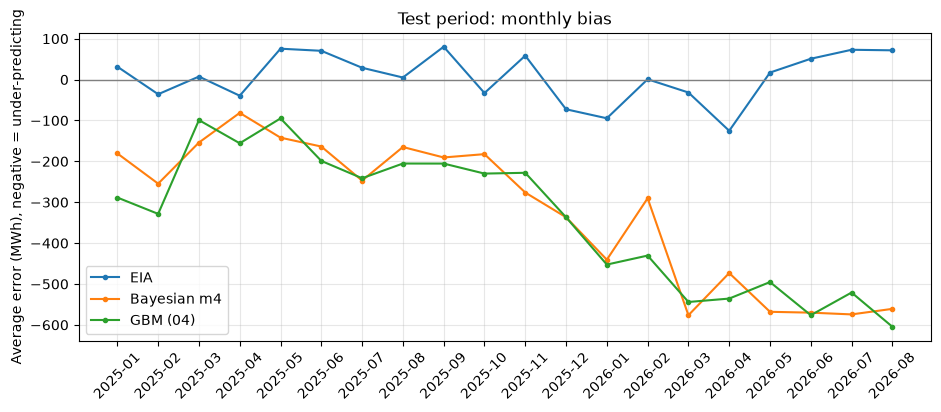

In [ ]:
#bias by month
#check forecast's miss change over the 20 months
err = pd.DataFrame({
    "EIA": preds["eia_forecast_mwh"] - preds["demand_mwh"],
    "Bayesian m4": preds["pred_bayes"] - preds["demand_mwh"],
    "GBM (04)": preds["pred_gbm"] - preds["demand_mwh"],
})[has_eia] #top three with eia data

bias_by_month = err.groupby(test_months[has_eia]).mean() #group by months with eia and average

fig, ax = plt.subplots(figsize=(11, 4))
for col in bias_by_month.columns:
    ax.plot(bias_by_month.index, bias_by_month[col], marker="o", markersize=3, label=col)

ax.axhline(0, color="gray", linewidth=1)
ax.set_ylabel("Average error (MWh), negative = under-predicting")
ax.set_title("Test period: monthly bias")
ax.tick_params(axis="x", labelrotation=45) #make dates read better
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Point forecast: about the same as the GBM, far behind EIA.**

| on the same 14,560 test hours | MAPE | bias (MWh) |
|---|---|---|
| EIA day-ahead | **1.94%** | +7 |
| GBM + weather-adjusted trend (04) | 4.86% | −338 |
| **Bayesian m4** | 4.93% | −322 |
| linear regression (04) | 5.34% | −346 |

- The Bayesian model lands right next to the GBM, as expected: same weather information, same kind of trend, and the same blind spot.
- The monthly bias tells the story of about −80 to −280 MWh through Jan–Nov 2025, then a step to about −290 to −580 MWh from Dec 2025 on. These are the same two step-ups notebook 04 found. EIA stays within about 125 MWh the whole time, probably because it sees recent demand and can use that.
- So the straight-line trend (116 MWh/yr) is far too slow for 2025–26. Notebook 03's Jan–Aug averages rose about 275 MWh into 2025 and about 320 more into 2026.

### Do the intervals hold up?
coverage of the 90% interval, month by month through the test period.

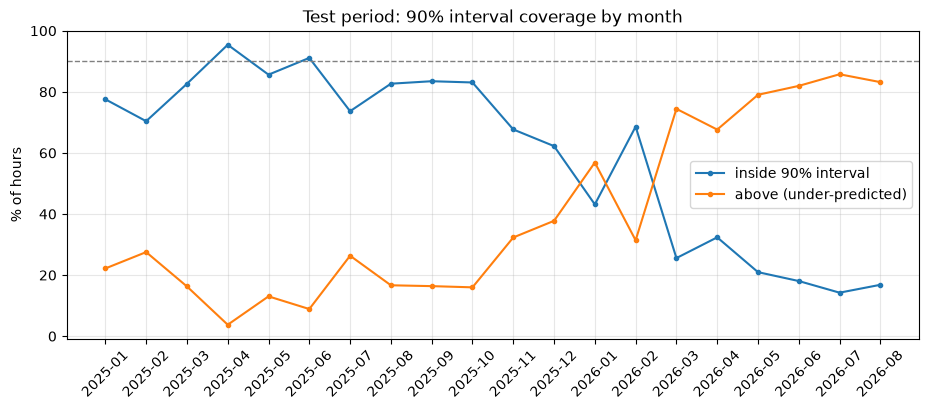

,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
coverage_pct,77.6,70.4,82.6,95.4,85.6,91.1,73.7,82.7,83.5,83.1,67.7,62.2,43.1,68.6,25.6,32.4,21.0,18.1,14.2,16.8
above_pct,22.2,27.5,16.3,3.8,13.0,8.9,26.3,16.7,16.4,16.0,32.3,37.8,56.9,31.4,74.4,67.6,79.0,81.9,85.8,83.2
width_mwh,866.9,866.9,768.6,768.8,768.6,739.3,738.9,739.0,762.8,762.6,762.5,866.8,866.8,867.3,768.6,769.1,768.7,739.0,739.8,739.4


In [ ]:
inside_test = (test["demand_mwh"].values >= cal_test["lo"]) & (test["demand_mwh"].values <= cal_test["hi"]) #get ranges to lie between

cov_by_month = pd.DataFrame({ #covereage of each month, *100 for percent
    "coverage_pct": pd.Series(inside_test).groupby(test_months).mean() * 100,
    "above_pct": pd.Series(test["demand_mwh"].values > cal_test["hi"]).groupby(test_months).mean() * 100,
    "width_mwh": pd.Series(cal_test["hi"] - cal_test["lo"]).groupby(test_months).mean(),
})

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(cov_by_month.index, cov_by_month["coverage_pct"], marker="o", markersize=3, label="inside 90% interval") #coverage
ax.plot(cov_by_month.index, cov_by_month["above_pct"], marker="o", markersize=3, label="above (under-predicted)") #under predictions

ax.axhline(90, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("% of hours")
ax.set_title("Test period: 90% interval coverage by month")
ax.tick_params(axis="x", labelrotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

cov_by_month.round(1).T

Do well until late 2025 to 2026 then we under predict

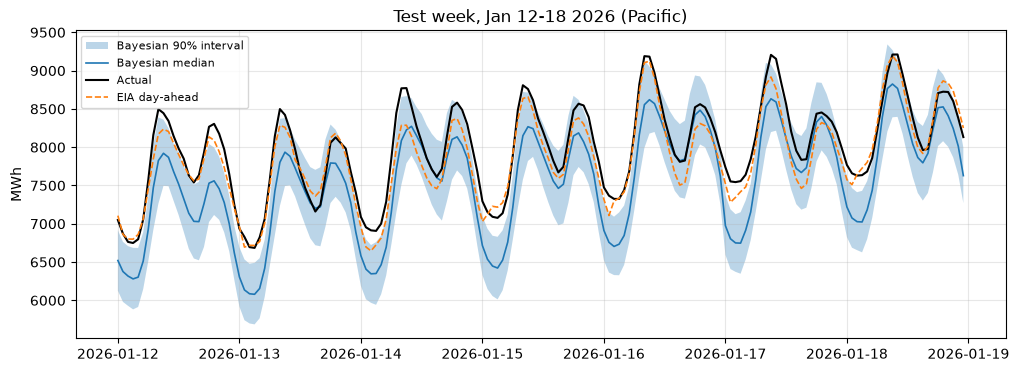

In [ ]:
#interval vs actual vs EIA for a winter week
week = (test["period_utc"] >= "2026-01-12 08:00:00+00") & (test["period_utc"] < "2026-01-19 08:00:00+00") #week to look at, can change, looked where we see it go under
t = test.loc[week, "period_utc"].dt.tz_convert("America/Los_Angeles")

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(t, cal_test["lo"][week.values], cal_test["hi"][week.values], alpha=0.3, label="Bayesian 90% interval") #interval
ax.plot(t, cal_test["med"][week.values], linewidth=1.2, label="Bayesian median")
ax.plot(t, test.loc[week, "demand_mwh"], color="black", linewidth=1.5, label="Actual")
ax.plot(t, test.loc[week, "eia_forecast_mwh"], linestyle="--", linewidth=1.2, label="EIA day-ahead")

ax.set_ylabel("MWh")
ax.set_title("Test week, Jan 12-18 2026 (Pacific)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.show()

The intervals don't hold up once the level shifts
- Overall coverage is 59.6%, not 90%. And the misses are almost all on one side: 40.0% of hours above the interval vs 0.4% below.
- By month it collapses in steps. 
    - It's mostly 70–95% in early-to-mid 2025, 62–68% in Nov–Dec 2025, and 14–33% from Mar 2026 on. 
    - By summer 2026, real demand is above the 90% interval more than 80% of the time.

- The width never reacts: ~740–870 MWh all the way through, the same as in 2024. The model has no way to know it's drifting, so it stays exactly as confident 20 months out as one month out.
- The January 2026 week plot shows what that looks like hour by hour.

This is the most useful result in the notebook. A forecast that's 4.9% off but says it might be is usable. 
A forecast that claims 90% and delivers 15% is not. The intervals are only honest while the level stays where training left it.

## Summary
**What the Bayesian model added over the GBM:**
- Effects with uncertainty: e.g. heating response per location, and visible credit-splitting when two locations carry the same information (Eugene).
- Prediction intervals that were well calibrated on 2024, by hour and nearly by month, once sigma varied by season x hour (Step 11).
- A clear diagnosis of what breaks out of sample: the coverage collapse pins the failure on the level, not the weather response or the noise.

What it didn't fix: the point forecast on 2025–26 (4.93% MAPE, about the GBM's 4.86%). showed that 2021–2023 alone can't reveal the coming level shifts.


**Caveats:** actual weather was used throughout, so all of these are best-case versus EIA's forecast-weather numbers. Hour-to-hour errors are strongly correlated (0.91), so intervals for whole days or peaks would be too narrow even where hourly coverage is fine.